# Phase 7 — Temporal Contamination Analysis

## Objective
Analyze historical groundwater chemical changes across India and investigate whether reliable location-specific temporal predictions can be developed.

## Main components

1. Historical nationwide chemical trends.
2. State-wise and district-wise temporal comparisons.
3. Location-specific time-series analysis using provisional spatial groups.
4. Identification of increasing, decreasing and stable chemical trends.
5. Future concentration forecasting where repeated observations support it.
6. Temporal validation using chronological separation.

## Core chemical parameters
- Potential of Hydrogen (pH)
- Electric Conductivity (μS/cm)
- Chloride (mg/L)
- Bicarbonate (mg/L)
- Sulphate (mg/L)
- Calcium (mg/L)
- Magnesium (mg/L)
- Sodium (mg/L)

## Methodological considerations
- Use the original data acquisition date for temporal analysis.
- Preserve original observations and source traceability.
- Use medians and distribution summaries to reduce sensitivity to extreme values.
- Account for uneven geographic and seasonal sampling.
- Use provisional spatial groups for repeated-location analysis.
- Avoid forecasting locations with insufficient temporal history.
- Keep future test periods separate from model training.

## Expected outputs
- Annual and monthly chemical trend reports.
- State-wise temporal analysis.
- Repeated-location coverage assessment.
- Location-specific trend classifications.
- Forecast models where sufficient historical data exists.
- Forecast evaluation and uncertainty analysis.

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate project root.
cwd = Path.cwd()

if (cwd / "data").exists() and (cwd / "reports").exists():
    PROJECT_ROOT = cwd
elif (
    (cwd.parent / "data").exists()
    and (cwd.parent / "reports").exists()
):
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Could not locate project root.")

MASTER_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "groundwater_master_processed.csv"
)

FEATURE_PATH = (
    PROJECT_ROOT
    / "reports"
    / "feature_engineering"
    / "classification_context_labels.csv"
)

for path in [MASTER_PATH, FEATURE_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path}")

# Load original integrated historical records.
temporal_source = pd.read_csv(
    MASTER_PATH,
    low_memory=False
)

# Inspect Phase 5 schema before loading metadata.
feature_columns = pd.read_csv(
    FEATURE_PATH,
    nrows=0
).columns.tolist()

metadata_columns = [
    "_record_id",
    "_spatial_group_id",
    "_state_feature",
    "_district_feature",
    "_geo_grid_id",
    "_latitude",
    "_longitude",
    "_coordinates_missing"
]

missing_metadata = [
    col for col in metadata_columns
    if col not in feature_columns
]

if missing_metadata:
    raise KeyError(
        f"Phase 5 metadata columns missing: {missing_metadata}"
    )

# Load only the required metadata columns.
temporal_metadata = pd.read_csv(
    FEATURE_PATH,
    usecols=metadata_columns,
    low_memory=False
)

# Confirm record identity integrity.
assert temporal_source["_record_id"].is_unique
assert temporal_metadata["_record_id"].is_unique

# Merge without removing any original records.
temporal_source = temporal_source.merge(
    temporal_metadata,
    on="_record_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

unmatched = (
    temporal_source["_merge"] != "both"
).sum()

print("TEMPORAL DATASET AND METADATA INTEGRATION")
print("=" * 65)
print(f"Original master records: {len(temporal_source):,}")
print(f"Metadata records: {len(temporal_metadata):,}")
print(f"Matched records: {(temporal_source['_merge'] == 'both').sum():,}")
print(f"Unmatched records: {unmatched:,}")

assert unmatched == 0, "Some master records lack Phase 5 metadata."

temporal_source.drop(columns="_merge", inplace=True)

TEMPORAL_TARGETS = [
    "Potential of Hydrogen (pH)",
    "Electric Conductivity (μS/cm)",
    "Chloride (mg/L)",
    "Bicarbonate (mg/L)",
    "Sulphate (mg/L)",
    "Calcium (mg/L)",
    "Magnesium (mg/L)",
    "Sodium (mg/L)"
]

REQUIRED_COLUMNS = [
    "_record_id",
    "_spatial_group_id",
    "_state_feature",
    "_district_feature",
    "Data Acquisition Time"
] + TEMPORAL_TARGETS

missing_columns = [
    col for col in REQUIRED_COLUMNS
    if col not in temporal_source.columns
]

if missing_columns:
    raise KeyError(f"Required columns missing: {missing_columns}")

print("\nTEMPORAL ANALYSIS DATASET READY")
print(f"Records: {len(temporal_source):,}")
print(f"Distinct spatial groups: {temporal_source['_spatial_group_id'].nunique():,}")
print(f"States/UTs: {temporal_source['_state_feature'].nunique():,}")
print(f"District labels: {temporal_source['_district_feature'].nunique():,}")

display(
    temporal_source[
        ["_record_id", "_spatial_group_id",
         "_state_feature", "_district_feature"]
    ].head()
)

TEMPORAL DATASET AND METADATA INTEGRATION
Original master records: 174,635
Metadata records: 174,635
Matched records: 174,635
Unmatched records: 0

TEMPORAL ANALYSIS DATASET READY
Records: 174,635
Distinct spatial groups: 24,199
States/UTs: 31
District labels: 593


C:\Users\pokep\AppData\Local\Temp\ipykernel_23612\3797625526.py:82: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  temporal_source = temporal_source.merge(
C:\Users\pokep\AppData\Local\Temp\ipykernel_23612\3797625526.py:82: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  temporal_source = temporal_source.merge(
C:\Users\pokep\AppData\Local\Temp\ipykernel_23612\3797625526.py:103: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/de

,_record_id,_spatial_group_id,_state_feature,_district_feature
0,gwq_chemical_parameter_manual_cgwb_an_1961_202...,andaman and nicobar islands|south andaman|anni...,andaman and nicobar islands,south andaman
1,gwq_chemical_parameter_manual_cgwb_an_1961_202...,andaman and nicobar islands|south andaman|anni...,andaman and nicobar islands,south andaman
2,gwq_chemical_parameter_manual_cgwb_an_1961_202...,andaman and nicobar islands|south andaman|anni...,andaman and nicobar islands,south andaman
3,gwq_chemical_parameter_manual_cgwb_an_1961_202...,andaman and nicobar islands|south andaman|anni...,andaman and nicobar islands,south andaman
4,gwq_chemical_parameter_manual_cgwb_an_1961_202...,andaman and nicobar islands|south andaman|anni...,andaman and nicobar islands,south andaman


In [5]:
temporal_df = temporal_source[REQUIRED_COLUMNS].copy()

temporal_df["_date"] = pd.to_datetime(
    temporal_df["Data Acquisition Time"].astype(str).str.strip(),
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

temporal_df["_year"] = temporal_df["_date"].dt.year
temporal_df["_month"] = temporal_df["_date"].dt.month
temporal_df["_year_month"] = (
    temporal_df["_date"].dt.to_period("M").astype(str)
)

# Convert all eight chemical targets to numeric.
for target in TEMPORAL_TARGETS:
    temporal_df[target] = pd.to_numeric(
        temporal_df[target],
        errors="coerce"
    )

# Parameter-specific validity screening.
# Extreme positive values remain preserved for investigation.
target_validity = {}

for target in TEMPORAL_TARGETS:
    values = temporal_df[target]

    valid = (
        values.notna()
        & np.isfinite(values)
        & (values >= 0)
    )

    if target == "Potential of Hydrogen (pH)":
        valid &= (values > 0) & (values <= 14)

    target_validity[target] = valid

print("DATE PARSING RESULTS")
print("=" * 60)

print(f"Total records: {len(temporal_df):,}")
print(f"Valid acquisition dates: {temporal_df['_date'].notna().sum():,}")
print(f"Invalid/missing dates: {temporal_df['_date'].isna().sum():,}")

valid_dates = temporal_df["_date"].dropna()

if len(valid_dates):
    print(f"Earliest date: {valid_dates.min()}")
    print(f"Latest date: {valid_dates.max()}")

print("\nVALID CHEMICAL OBSERVATIONS")
print("-" * 60)

validity_summary = pd.DataFrame({
    "Valid observations": {
        t: int(target_validity[t].sum())
        for t in TEMPORAL_TARGETS
    },
    "Invalid or missing": {
        t: int((~target_validity[t]).sum())
        for t in TEMPORAL_TARGETS
    }
})

display(validity_summary)

DATE PARSING RESULTS
Total records: 174,635
Valid acquisition dates: 174,635
Invalid/missing dates: 0
Earliest date: 2000-05-25 00:00:00
Latest date: 2025-05-08 10:02:00

VALID CHEMICAL OBSERVATIONS
------------------------------------------------------------


,Valid observations,Invalid or missing
Potential of Hydrogen (pH),162719,11916
Electric Conductivity (μS/cm),173029,1606
Chloride (mg/L),162033,12602
Bicarbonate (mg/L),147170,27465
Sulphate (mg/L),126326,48309
Calcium (mg/L),149855,24780
Magnesium (mg/L),150412,24223
Sodium (mg/L),143470,31165


In [6]:
dated_df = temporal_df.loc[
    temporal_df["_date"].notna()
].copy()

# Nationwide annual coverage.
annual_summary = (
    dated_df.groupby("_year")
    .agg(
        Total_records=("_record_id", "size"),
        Spatial_groups=("_spatial_group_id", "nunique"),
        States=("_state_feature", "nunique"),
        Months_observed=("_month", "nunique")
    )
)

annual_summary.index = annual_summary.index.astype(int)

print("NATIONWIDE ANNUAL SAMPLING COVERAGE")
print("=" * 70)
display(annual_summary)

# Annual availability for each core target.
annual_target_counts = {}

for target in TEMPORAL_TARGETS:
    valid = dated_df.loc[target_validity[target].loc[dated_df.index]]

    annual_target_counts[target] = (
        valid.groupby("_year")
        .size()
        .rename(target)
    )

annual_target_summary = pd.DataFrame(
    annual_target_counts
).fillna(0).astype(int)

annual_target_summary.index = annual_target_summary.index.astype(int)

print("\nANNUAL VALID CHEMICAL OBSERVATIONS")
print("=" * 70)
display(annual_target_summary)

# Month-wise sampling distribution.
monthly_summary = (
    dated_df.groupby("_month")
    .agg(
        Records=("_record_id", "size"),
        Spatial_groups=("_spatial_group_id", "nunique")
    )
)

monthly_summary["Record percentage"] = (
    monthly_summary["Records"]
    / monthly_summary["Records"].sum()
    * 100
)

print("\nMONTHLY SAMPLING DISTRIBUTION")
print("=" * 70)
display(monthly_summary.round(2))

print(
    "\nPercentage of all observations collected in May:",
    round(monthly_summary.loc[5, "Record percentage"], 2)
    if 5 in monthly_summary.index else 0,
    "%"
)

NATIONWIDE ANNUAL SAMPLING COVERAGE


,Total_records,Spatial_groups,States,Months_observed
_year,,,,
2000,6645,6645,27,1
2001,5747,5746,23,1
2002,6862,6858,24,1
2003,6486,6486,25,1
2004,7332,7332,24,1
2005,6215,6215,30,1
2006,6022,6021,28,1
2007,6662,6661,28,1
2008,6649,6649,27,1



ANNUAL VALID CHEMICAL OBSERVATIONS


,Potential of Hydrogen (pH),Electric Conductivity (μS/cm),Chloride (mg/L),Bicarbonate (mg/L),Sulphate (mg/L),Calcium (mg/L),Magnesium (mg/L),Sodium (mg/L)
_year,,,,,,,,
2000,5505,6643,6472,5340,4800,5515,5513,5209
2001,4824,5076,5063,4533,3539,4316,4313,4034
2002,6321,6857,6679,4502,3539,4514,4506,4210
2003,1377,6441,485,484,204,483,484,475
2004,6770,7330,7270,6056,5573,6091,6098,6067
2005,5677,6204,5886,5515,5051,5518,5531,5268
2006,5497,6014,5741,4947,4626,5424,5415,4685
2007,6514,6657,6401,6404,6043,6545,6530,6290
2008,6199,6277,6036,5220,4938,5496,5508,4800



MONTHLY SAMPLING DISTRIBUTION


,Records,Spatial_groups,Record percentage
_month,,,
1,1,1,0.00
2,50,49,0.03
3,2,2,0.00
4,277,277,0.16
5,170967,23933,97.90
6,2297,1759,1.32
7,36,36,0.02
8,243,243,0.14
9,4,4,0.00



Percentage of all observations collected in May: 97.9 %


In [7]:
location_support = {}
support_rows = []

for target in TEMPORAL_TARGETS:

    valid = temporal_df.loc[
        target_validity[target]
        & temporal_df["_date"].notna()
        & temporal_df["_spatial_group_id"].notna()
    ].copy()

    group_stats = (
        valid.groupby("_spatial_group_id")
        .agg(
            Total_records=("_record_id", "size"),
            Distinct_dates=("_date", "nunique"),
            Distinct_years=("_year", "nunique"),
            First_observation=("_date", "min"),
            Last_observation=("_date", "max")
        )
    )

    group_stats["Span_years"] = (
        group_stats["Last_observation"]
        - group_stats["First_observation"]
    ).dt.days / 365.25

    location_support[target] = group_stats

    support_rows.append({
        "Target": target,
        "Valid observations": len(valid),
        "Spatial groups sampled": len(group_stats),
        "Groups with 2+ distinct dates": int(
            (group_stats["Distinct_dates"] >= 2).sum()
        ),
        "Groups with 3+ distinct dates": int(
            (group_stats["Distinct_dates"] >= 3).sum()
        ),
        "Groups with 3+ distinct years": int(
            (group_stats["Distinct_years"] >= 3).sum()
        ),
        "Groups with 5+ distinct years": int(
            (group_stats["Distinct_years"] >= 5).sum()
        ),
        "Groups with 3+ years and 2+ year span": int(
            (
                (group_stats["Distinct_years"] >= 3)
                & (group_stats["Span_years"] >= 2)
            ).sum()
        ),
        "Groups with 5+ years and 4+ year span": int(
            (
                (group_stats["Distinct_years"] >= 5)
                & (group_stats["Span_years"] >= 4)
            ).sum()
        )
    })

location_support_summary = (
    pd.DataFrame(support_rows)
    .set_index("Target")
)

print("REPEATED-LOCATION TEMPORAL SUPPORT")
print("=" * 90)
display(location_support_summary)

print("\nInterpretation:")
print("- 2+ distinct dates indicate repeated observations.")
print("- 3+ distinct years provide preliminary trend-analysis support.")
print("- 5+ distinct years across 4+ years provide stronger historical support.")
print("- These are screening criteria, not automatic proof of forecastability.")

REPEATED-LOCATION TEMPORAL SUPPORT


,Valid observations,Spatial groups sampled,Groups with 2+ distinct dates,Groups with 3+ distinct dates,Groups with 3+ distinct years,Groups with 5+ distinct years,Groups with 3+ years and 2+ year span,Groups with 5+ years and 4+ year span
Target,,,,,,,,
Potential of Hydrogen (pH),162719,23692,19866,17130,17108,13170,16961,13163
Electric Conductivity (μS/cm),173029,24117,20331,17543,17522,13597,17388,13590
Chloride (mg/L),162033,23674,19838,17103,17081,13083,16938,13076
Bicarbonate (mg/L),147170,23174,19250,16381,16352,12009,16205,12002
Sulphate (mg/L),126326,21967,17242,14580,14534,10421,14393,10417
Calcium (mg/L),149855,23343,19358,16500,16470,12194,16323,12187
Magnesium (mg/L),150412,23341,19356,16497,16467,12207,16321,12200
Sodium (mg/L),143470,23027,19113,16251,16221,11816,16069,11809



Interpretation:
- 2+ distinct dates indicate repeated observations.
- 3+ distinct years provide preliminary trend-analysis support.
- 5+ distinct years across 4+ years provide stronger historical support.
- These are screening criteria, not automatic proof of forecastability.


In [8]:
# Primary analysis period.
ANALYSIS_START_YEAR = 2000
ANALYSIS_END_YEAR = 2023

analysis_df = temporal_df.loc[
    temporal_df["_date"].notna()
    & temporal_df["_year"].between(
        ANALYSIS_START_YEAR,
        ANALYSIS_END_YEAR
    )
].copy()

annual_statistics = {}
annual_counts = {}

for target in TEMPORAL_TARGETS:

    valid_mask = target_validity[target].loc[analysis_df.index]

    valid_data = analysis_df.loc[
        valid_mask,
        ["_year", target]
    ]

    stats = (
        valid_data.groupby("_year")[target]
        .agg(
            Count="count",
            Median="median",
            Q25=lambda x: x.quantile(0.25),
            Q75=lambda x: x.quantile(0.75)
        )
    )

    annual_statistics[target] = stats["Median"]
    annual_counts[target] = stats["Count"]

annual_median_df = pd.DataFrame(annual_statistics)
annual_count_df = pd.DataFrame(annual_counts)

print("NATIONWIDE ANNUAL MEDIAN CHEMICAL CONCENTRATIONS")
print("=" * 85)
display(annual_median_df.round(3))

print("\nANNUAL VALID OBSERVATION COUNTS")
print("=" * 85)
display(annual_count_df)

print("\nANALYSIS PERIOD")
print(f"Start year: {ANALYSIS_START_YEAR}")
print(f"End year: {ANALYSIS_END_YEAR}")
print(f"Total records in analysis period: {len(analysis_df):,}")

NATIONWIDE ANNUAL MEDIAN CHEMICAL CONCENTRATIONS


,Potential of Hydrogen (pH),Electric Conductivity (μS/cm),Chloride (mg/L),Bicarbonate (mg/L),Sulphate (mg/L),Calcium (mg/L),Magnesium (mg/L),Sodium (mg/L)
_year,,,,,,,,
2000,7.900,877.00,82.000,305.000,55.00,51.0,34.000,80.00
2001,7.880,905.00,80.000,293.000,40.00,48.0,30.000,64.00
2002,7.940,820.00,74.000,281.000,38.00,52.0,28.000,68.00
2003,7.700,716.00,57.000,220.000,62.00,48.0,28.020,57.00
2004,7.900,791.00,67.400,268.000,35.00,46.0,29.000,55.00
2005,7.850,782.00,71.000,256.000,42.00,48.0,29.260,62.00
2006,7.900,835.00,85.000,250.000,50.00,46.0,27.000,80.00
2007,7.800,837.00,74.000,268.000,34.00,44.0,28.040,62.00
2008,7.900,777.00,70.900,271.000,40.00,46.0,28.300,70.00



ANNUAL VALID OBSERVATION COUNTS


,Potential of Hydrogen (pH),Electric Conductivity (μS/cm),Chloride (mg/L),Bicarbonate (mg/L),Sulphate (mg/L),Calcium (mg/L),Magnesium (mg/L),Sodium (mg/L)
_year,,,,,,,,
2000,5505,6643,6472,5340,4800,5515,5513,5209
2001,4824,5076,5063,4533,3539,4316,4313,4034
2002,6321,6857,6679,4502,3539,4514,4506,4210
2003,1377,6441,485,484,204,483,484,475
2004,6770,7330,7270,6056,5573,6091,6098,6067
2005,5677,6204,5886,5515,5051,5518,5531,5268
2006,5497,6014,5741,4947,4626,5424,5415,4685
2007,6514,6657,6401,6404,6043,6545,6530,6290
2008,6199,6277,6036,5220,4938,5496,5508,4800



ANALYSIS PERIOD
Start year: 2000
End year: 2023
Total records in analysis period: 174,619


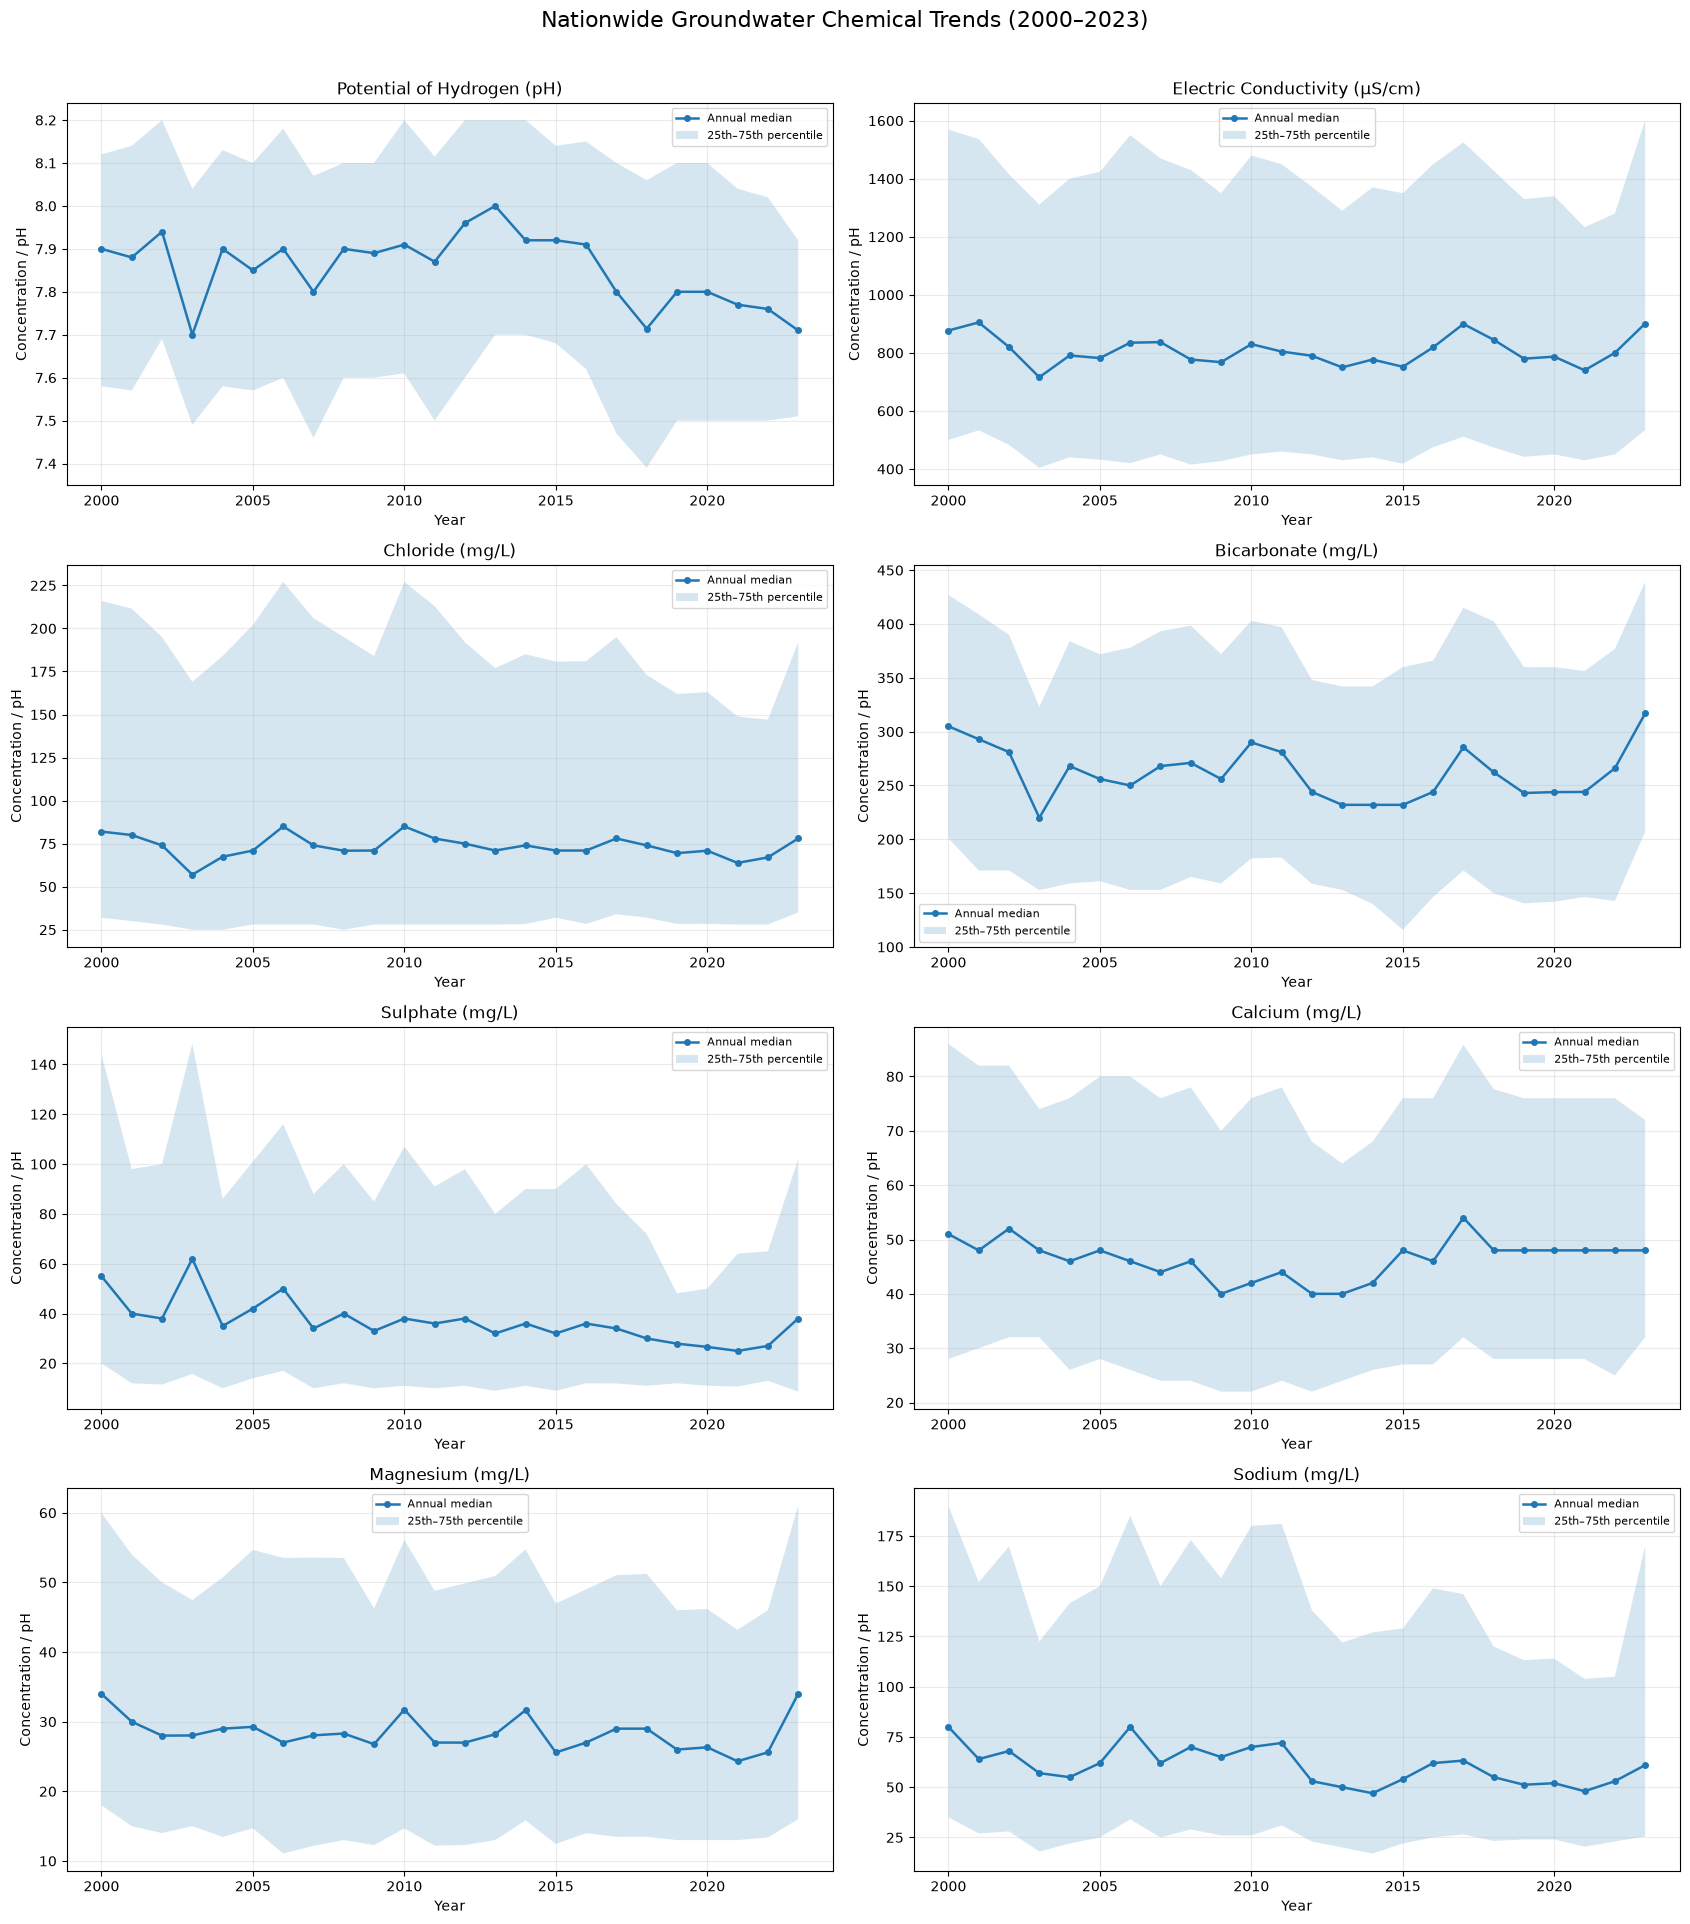

In [9]:
fig, axes = plt.subplots(4, 2, figsize=(17, 19))
axes = axes.flatten()

for ax, target in zip(axes, TEMPORAL_TARGETS):

    valid_mask = target_validity[target].loc[analysis_df.index]

    valid_data = analysis_df.loc[
        valid_mask,
        ["_year", target]
    ]

    stats = (
        valid_data.groupby("_year")[target]
        .agg(
            Median="median",
            Q25=lambda x: x.quantile(0.25),
            Q75=lambda x: x.quantile(0.75)
        )
    )

    years = stats.index.to_numpy()

    ax.plot(
        years,
        stats["Median"],
        marker="o",
        markersize=4,
        linewidth=1.8,
        label="Annual median"
    )

    ax.fill_between(
        years,
        stats["Q25"].to_numpy(),
        stats["Q75"].to_numpy(),
        alpha=0.18,
        label="25th–75th percentile"
    )

    ax.set_title(target)
    ax.set_xlabel("Year")
    ax.set_ylabel("Concentration / pH")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.suptitle(
    "Nationwide Groundwater Chemical Trends (2000–2023)",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

In [10]:
location_year_panels = {}
panel_support_rows = []

for target in TEMPORAL_TARGETS:

    valid_mask = target_validity[target].loc[analysis_df.index]

    valid_data = analysis_df.loc[
        valid_mask,
        ["_spatial_group_id", "_year", target]
    ].copy()

    # One median value per spatial group per year.
    group_year = (
        valid_data.groupby(
            ["_spatial_group_id", "_year"]
        )[target]
        .median()
        .reset_index()
    )

    # Establish how much historical coverage each group has.
    group_history = (
        group_year.groupby("_spatial_group_id")
        .agg(
            Distinct_years=("_year", "nunique"),
            First_year=("_year", "min"),
            Last_year=("_year", "max")
        )
    )

    group_history["Year_span"] = (
        group_history["Last_year"]
        - group_history["First_year"]
    )

    eligible_groups = group_history.index[
        (group_history["Distinct_years"] >= 5)
        & (group_history["Year_span"] >= 4)
    ]

    # Keep only qualifying historical locations.
    target_panel = group_year[
        group_year["_spatial_group_id"].isin(eligible_groups)
    ].copy()

    location_year_panels[target] = target_panel

    panel_support_rows.append({
        "Target": target,
        "Eligible spatial groups": len(eligible_groups),
        "Group-year observations": len(target_panel),
        "Earliest year": (
            target_panel["_year"].min()
            if len(target_panel) else np.nan
        ),
        "Latest year": (
            target_panel["_year"].max()
            if len(target_panel) else np.nan
        ),
        "Median years per group": (
            target_panel.groupby("_spatial_group_id")["_year"]
            .nunique().median()
            if len(target_panel) else np.nan
        )
    })

panel_support_df = (
    pd.DataFrame(panel_support_rows)
    .set_index("Target")
)

print("REPEATED-LOCATION HISTORICAL PANEL")
print("=" * 85)
display(panel_support_df.round(2))

print("\nPanel construction:")
print("- One observation per provisional spatial group per year.")
print("- Annual median used to reduce sensitivity to extreme measurements.")
print("- At least five distinct years required.")
print("- At least four years between first and last observations required.")
print("- Panels are unbalanced: groups need not be observed in every year.")

REPEATED-LOCATION HISTORICAL PANEL


,Eligible spatial groups,Group-year observations,Earliest year,Latest year,Median years per group
Target,,,,,
Potential of Hydrogen (pH),13169,139064,2000,2023,9.0
Electric Conductivity (μS/cm),13596,149352,2000,2023,10.0
Chloride (mg/L),13082,138166,2000,2023,9.0
Bicarbonate (mg/L),12008,121727,2000,2023,9.0
Sulphate (mg/L),10419,101224,2000,2023,8.0
Calcium (mg/L),12193,124611,2000,2023,9.0
Magnesium (mg/L),12206,125218,2000,2023,9.0
Sodium (mg/L),11815,117850,2000,2023,9.0



Panel construction:
- One observation per provisional spatial group per year.
- Annual median used to reduce sensitivity to extreme measurements.
- At least five distinct years required.
- At least four years between first and last observations required.
- Panels are unbalanced: groups need not be observed in every year.


In [11]:
from scipy.stats import kendalltau, theilslopes
from time import perf_counter
import warnings

trend_result_rows = []

print("LOCATION-SPECIFIC TREND ANALYSIS")
print("=" * 70)

overall_start = perf_counter()

for target in TEMPORAL_TARGETS:

    panel = location_year_panels[target]

    print(
        f"\nProcessing {target}: "
        f"{panel['_spatial_group_id'].nunique():,} locations"
    )

    target_start = perf_counter()

    for group_id, group_data in panel.groupby(
        "_spatial_group_id",
        sort=False
    ):

        group_data = group_data.sort_values("_year")

        years = group_data["_year"].to_numpy(dtype=float)
        values = group_data[target].to_numpy(dtype=float)

        if len(years) < 5 or len(np.unique(years)) < 5:
            continue

        # Handle constant-valued time series separately.
        if np.all(values == values[0]):
            slope = 0.0
            tau = 0.0
            p_value = 1.0
        else:
            slope = float(
                theilslopes(values, x=years).slope
            )

            kendall_result = kendalltau(
                years,
                values,
                variant="b"
            )

            tau = float(kendall_result.statistic)
            p_value = float(kendall_result.pvalue)

        trend_result_rows.append({
            "Target": target,
            "_spatial_group_id": group_id,
            "Observation_years": len(years),
            "First_year": int(years.min()),
            "Last_year": int(years.max()),
            "Year_span": int(years.max() - years.min()),
            "Theil_Sen_slope_per_year": slope,
            "Kendall_tau": tau,
            "Mann_Kendall_p_value": p_value,
            "Historical_median": float(np.median(values))
        })

    print(
        f"Completed in {perf_counter() - target_start:.1f} seconds"
    )

trend_results_df = pd.DataFrame(trend_result_rows)

print("\n" + "=" * 70)
print("TREND CALCULATION COMPLETED")
print(f"Location-target combinations: {len(trend_results_df):,}")
print(f"Elapsed time: {perf_counter() - overall_start:.1f} seconds")

display(
    trend_results_df.groupby("Target").size()
    .rename("Analyzed spatial groups")
    .to_frame()
)

LOCATION-SPECIFIC TREND ANALYSIS

Processing Potential of Hydrogen (pH): 13,169 locations
Completed in 22.2 seconds

Processing Electric Conductivity (μS/cm): 13,596 locations
Completed in 23.0 seconds

Processing Chloride (mg/L): 13,082 locations
Completed in 22.0 seconds

Processing Bicarbonate (mg/L): 12,008 locations
Completed in 20.2 seconds

Processing Sulphate (mg/L): 10,419 locations
Completed in 17.8 seconds

Processing Calcium (mg/L): 12,193 locations
Completed in 20.7 seconds

Processing Magnesium (mg/L): 12,206 locations
Completed in 20.9 seconds

Processing Sodium (mg/L): 11,815 locations
Completed in 20.0 seconds

TREND CALCULATION COMPLETED
Location-target combinations: 98,488
Elapsed time: 166.9 seconds


,Analyzed spatial groups
Target,
Bicarbonate (mg/L),12008
Calcium (mg/L),12193
Chloride (mg/L),13082
Electric Conductivity (μS/cm),13596
Magnesium (mg/L),12206
Potential of Hydrogen (pH),13169
Sodium (mg/L),11815
Sulphate (mg/L),10419


In [12]:
def benjamini_hochberg(p_values):

    p = np.asarray(p_values, dtype=float)

    adjusted = np.full(len(p), np.nan)

    valid_mask = np.isfinite(p)
    valid_positions = np.where(valid_mask)[0]

    valid_p = p[valid_mask]
    m = len(valid_p)

    if m == 0:
        return adjusted

    order = np.argsort(valid_p)
    sorted_p = valid_p[order]

    ranks = np.arange(1, m + 1)

    sorted_q = sorted_p * m / ranks

    # Enforce monotonic adjusted p-values.
    sorted_q = np.minimum.accumulate(sorted_q[::-1])[::-1]
    sorted_q = np.clip(sorted_q, 0, 1)

    corrected_values = np.empty(m)
    corrected_values[order] = sorted_q

    adjusted[valid_positions] = corrected_values

    return adjusted


trend_results_df["BH_q_value"] = np.nan

# Correct p-values separately for each chemical parameter.
for target in TEMPORAL_TARGETS:

    mask = trend_results_df["Target"] == target

    trend_results_df.loc[mask, "BH_q_value"] = (
        benjamini_hochberg(
            trend_results_df.loc[
                mask, "Mann_Kendall_p_value"
            ].to_numpy()
        )
    )

# Use an exploratory significance threshold.
ALPHA = 0.05

increasing = (
    (trend_results_df["BH_q_value"] < ALPHA)
    & (trend_results_df["Theil_Sen_slope_per_year"] > 0)
)

decreasing = (
    (trend_results_df["BH_q_value"] < ALPHA)
    & (trend_results_df["Theil_Sen_slope_per_year"] < 0)
)

trend_results_df["Trend_classification"] = np.select(
    [increasing, decreasing],
    ["Increasing", "Decreasing"],
    default="No significant monotonic trend detected"
)

print("TREND CLASSIFICATION COMPLETED")
print("=" * 70)
print("Statistical method: Mann-Kendall")
print("Slope method: Theil-Sen")
print("Multiple-testing correction: Benjamini-Hochberg")
print(f"FDR significance threshold: {ALPHA}")

print("\nSample results:")
display(
    trend_results_df[
        [
            "Target",
            "Observation_years",
            "Theil_Sen_slope_per_year",
            "Kendall_tau",
            "Mann_Kendall_p_value",
            "BH_q_value",
            "Trend_classification"
        ]
    ].head(15).round(5)
)

TREND CLASSIFICATION COMPLETED
Statistical method: Mann-Kendall
Slope method: Theil-Sen
Multiple-testing correction: Benjamini-Hochberg
FDR significance threshold: 0.05

Sample results:


,Target,Observation_years,Theil_Sen_slope_per_year,Kendall_tau,Mann_Kendall_p_value,BH_q_value,Trend_classification
0,Potential of Hydrogen (pH),8,-0.03279,-0.32733,0.26183,0.69602,No significant monotonic trend detected
1,Potential of Hydrogen (pH),7,-0.06357,-0.55069,0.09091,0.53122,No significant monotonic trend detected
2,Potential of Hydrogen (pH),7,-0.02000,-0.39036,0.22426,0.68741,No significant monotonic trend detected
3,Potential of Hydrogen (pH),5,-0.00393,0.00000,1.00000,1.00000,No significant monotonic trend detected
4,Potential of Hydrogen (pH),8,-0.04527,-0.54554,0.06146,0.49446,No significant monotonic trend detected
5,Potential of Hydrogen (pH),8,-0.03488,-0.54554,0.06146,0.49446,No significant monotonic trend detected
6,Potential of Hydrogen (pH),5,-0.00994,-0.52705,0.20651,0.67551,No significant monotonic trend detected
7,Potential of Hydrogen (pH),8,-0.05167,-0.61828,0.03405,0.41251,No significant monotonic trend detected
8,Potential of Hydrogen (pH),7,-0.03235,-0.58554,0.06831,0.50583,No significant monotonic trend detected
9,Potential of Hydrogen (pH),8,-0.01745,-0.44475,0.13159,0.58025,No significant monotonic trend detected


In [13]:
trend_summary = (
    trend_results_df
    .groupby(["Target", "Trend_classification"])
    .agg(
        Spatial_groups=("_spatial_group_id", "count"),
        Median_slope=("Theil_Sen_slope_per_year", "median"),
        Median_Kendall_tau=("Kendall_tau", "median"),
        Median_q_value=("BH_q_value", "median")
    )
    .reset_index()
)

trend_counts = (
    trend_results_df
    .groupby(["Target", "Trend_classification"])
    .size()
    .unstack(fill_value=0)
)

trend_counts["Total analyzed"] = trend_counts.sum(axis=1)

trend_percentages = (
    trend_counts
    .drop(columns="Total analyzed")
    .div(trend_counts["Total analyzed"], axis=0)
    * 100
)

print("SPATIAL-GROUP TREND CLASSIFICATION")
print("=" * 85)
display(trend_counts)

print("\nPERCENTAGE DISTRIBUTION")
print("=" * 85)
display(trend_percentages.round(2))

print("\nTREND SLOPE SUMMARY")
print("=" * 85)
display(trend_summary.round(5))

SPATIAL-GROUP TREND CLASSIFICATION


Trend_classification,Decreasing,Increasing,No significant monotonic trend detected,Total analyzed
Target,,,,
Bicarbonate (mg/L),0,0,12008,12008
Calcium (mg/L),0,1,12192,12193
Chloride (mg/L),56,72,12954,13082
Electric Conductivity (μS/cm),43,92,13461,13596
Magnesium (mg/L),2,1,12203,12206
Potential of Hydrogen (pH),0,0,13169,13169
Sodium (mg/L),0,7,11808,11815
Sulphate (mg/L),0,0,10419,10419



PERCENTAGE DISTRIBUTION


Trend_classification,Decreasing,Increasing,No significant monotonic trend detected
Target,,,
Bicarbonate (mg/L),0.00,0.00,100.00
Calcium (mg/L),0.00,0.01,99.99
Chloride (mg/L),0.43,0.55,99.02
Electric Conductivity (μS/cm),0.32,0.68,99.01
Magnesium (mg/L),0.02,0.01,99.98
Potential of Hydrogen (pH),0.00,0.00,100.00
Sodium (mg/L),0.00,0.06,99.94
Sulphate (mg/L),0.00,0.00,100.00



TREND SLOPE SUMMARY


,Target,Trend_classification,Spatial_groups,Median_slope,Median_Kendall_tau,Median_q_value
0,Bicarbonate (mg/L),No significant monotonic trend detected,12008,1.00000,0.06667,0.80149
1,Calcium (mg/L),Increasing,1,0.53333,0.83583,0.00511
2,Calcium (mg/L),No significant monotonic trend detected,12192,0.08598,0.04740,0.76063
3,Chloride (mg/L),Decreasing,56,-13.86031,-0.71593,0.03720
4,Chloride (mg/L),Increasing,72,5.08167,0.70854,0.03468
5,Chloride (mg/L),No significant monotonic trend detected,12954,0.01658,0.03644,0.72873
6,Electric Conductivity (μS/cm),Decreasing,43,-55.50000,-0.67033,0.03533
7,Electric Conductivity (μS/cm),Increasing,92,34.60795,0.68990,0.02654
8,Electric Conductivity (μS/cm),No significant monotonic trend detected,13461,2.91667,0.07038,0.72721
9,Magnesium (mg/L),Decreasing,2,-4.58263,-0.73861,0.04338


In [14]:
may_trend_rows = []

may_df = analysis_df.loc[
    analysis_df["_month"] == 5
].copy()

print("MAY-ONLY LOCATION TREND ANALYSIS")
print("=" * 70)
print("May observations:", f"{len(may_df):,}")

for target in TEMPORAL_TARGETS:

    valid_mask = target_validity[target].loc[may_df.index]

    valid = may_df.loc[
        valid_mask,
        ["_spatial_group_id", "_year", target]
    ].copy()

    may_panel = (
        valid.groupby(["_spatial_group_id", "_year"])[target]
        .median()
        .reset_index()
    )

    group_support = (
        may_panel.groupby("_spatial_group_id")
        .agg(
            Distinct_years=("_year", "nunique"),
            First_year=("_year", "min"),
            Last_year=("_year", "max")
        )
    )

    group_support["Year_span"] = (
        group_support["Last_year"] - group_support["First_year"]
    )

    eligible_ids = group_support.index[
        (group_support["Distinct_years"] >= 5)
        & (group_support["Year_span"] >= 4)
    ]

    eligible_panel = may_panel[
        may_panel["_spatial_group_id"].isin(eligible_ids)
    ]

    print(f"\n{target}: {len(eligible_ids):,} eligible locations")

    for group_id, data in eligible_panel.groupby(
        "_spatial_group_id",
        sort=False
    ):

        data = data.sort_values("_year")

        years = data["_year"].to_numpy(dtype=float)
        values = data[target].to_numpy(dtype=float)

        if np.all(values == values[0]):
            slope, tau, p_value = 0.0, 0.0, 1.0
        else:
            slope = float(theilslopes(values, x=years).slope)

            result = kendalltau(
                years,
                values,
                variant="b"
            )

            tau = float(result.statistic)
            p_value = float(result.pvalue)

        may_trend_rows.append({
            "Target": target,
            "_spatial_group_id": group_id,
            "Observation_years": len(years),
            "First_year": int(years.min()),
            "Last_year": int(years.max()),
            "Year_span": int(years.max() - years.min()),
            "Theil_Sen_slope_per_year": slope,
            "Kendall_tau": tau,
            "Mann_Kendall_p_value": p_value,
            "Historical_median": float(np.median(values))
        })

may_trend_results_df = pd.DataFrame(may_trend_rows)

# Apply separate multiple-testing correction for each target.
may_trend_results_df["BH_q_value"] = np.nan

for target in TEMPORAL_TARGETS:

    mask = may_trend_results_df["Target"] == target

    may_trend_results_df.loc[mask, "BH_q_value"] = (
        benjamini_hochberg(
            may_trend_results_df.loc[
                mask, "Mann_Kendall_p_value"
            ].to_numpy()
        )
    )

may_increasing = (
    (may_trend_results_df["BH_q_value"] < ALPHA)
    & (may_trend_results_df["Theil_Sen_slope_per_year"] > 0)
)

may_decreasing = (
    (may_trend_results_df["BH_q_value"] < ALPHA)
    & (may_trend_results_df["Theil_Sen_slope_per_year"] < 0)
)

may_trend_results_df["Trend_classification"] = np.select(
    [may_increasing, may_decreasing],
    ["Increasing", "Decreasing"],
    default="No significant monotonic trend detected"
)

print("\nMAY-ONLY TREND ANALYSIS COMPLETED")
print("Location-target combinations:", f"{len(may_trend_results_df):,}")

MAY-ONLY LOCATION TREND ANALYSIS
May observations: 170,960

Potential of Hydrogen (pH): 13,027 eligible locations

Electric Conductivity (μS/cm): 13,455 eligible locations

Chloride (mg/L): 12,939 eligible locations

Bicarbonate (mg/L): 11,859 eligible locations

Sulphate (mg/L): 10,272 eligible locations

Calcium (mg/L): 12,044 eligible locations

Magnesium (mg/L): 12,058 eligible locations

Sodium (mg/L): 11,663 eligible locations

MAY-ONLY TREND ANALYSIS COMPLETED
Location-target combinations: 97,317


In [15]:
comparison_rows = []

for target in TEMPORAL_TARGETS:

    all_target = trend_results_df[
        trend_results_df["Target"] == target
    ].set_index("_spatial_group_id")

    may_target = may_trend_results_df[
        may_trend_results_df["Target"] == target
    ].set_index("_spatial_group_id")

    common = all_target.join(
        may_target,
        how="inner",
        lsuffix="_all",
        rsuffix="_may"
    )

    all_sig = set(
        all_target.index[
            all_target["BH_q_value"] < ALPHA
        ]
    )

    may_sig = set(
        may_target.index[
            may_target["BH_q_value"] < ALPHA
        ]
    )

    common_sig = all_sig & may_sig

    same_direction = sum(
        all_target.loc[group_id, "Trend_classification"]
        == may_target.loc[group_id, "Trend_classification"]
        for group_id in common_sig
    )

    comparison_rows.append({
        "Target": target,
        "All-month eligible groups": len(all_target),
        "May-only eligible groups": len(may_target),
        "Common eligible groups": len(common),
        "All-month significant": len(all_sig),
        "May-only significant": len(may_sig),
        "Significant in both": len(common_sig),
        "Same direction in both": same_direction
    })

may_sensitivity_df = (
    pd.DataFrame(comparison_rows)
    .set_index("Target")
)

print("ALL-MONTH VS MAY-ONLY TREND SENSITIVITY")
print("=" * 85)
display(may_sensitivity_df)

print("\nMAY-ONLY TREND CLASSIFICATIONS")
may_counts = (
    may_trend_results_df
    .groupby(["Target", "Trend_classification"])
    .size()
    .unstack(fill_value=0)
)

display(may_counts)

print("\nInterpretation:")
print("- Significant in both indicates repeatable statistical evidence.")
print("- Same direction in both indicates consistency of trend direction.")
print("- May-only and all-month results may differ because their eligible")
print("  location sets and observation counts differ.")

ALL-MONTH VS MAY-ONLY TREND SENSITIVITY


C:\Users\pokep\AppData\Local\Temp\ipykernel_23612\1360265014.py:13: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  common = all_target.join(
C:\Users\pokep\AppData\Local\Temp\ipykernel_23612\1360265014.py:13: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  common = all_target.join(
C:\Users\pokep\AppData\Local\Temp\ipykernel_23612\1360265014.py:13: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  common = all_target.join(
C:\Users\pokep\AppData\Local\Temp\ipykernel_23612\1360265014.py:13: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword i

,All-month eligible groups,May-only eligible groups,Common eligible groups,All-month significant,May-only significant,Significant in both,Same direction in both
Target,,,,,,,
Potential of Hydrogen (pH),13169,13027,13027,0,0,0,0
Electric Conductivity (μS/cm),13596,13455,13455,135,140,131,131
Chloride (mg/L),13082,12939,12939,128,128,124,124
Bicarbonate (mg/L),12008,11859,11859,0,0,0,0
Sulphate (mg/L),10419,10272,10272,0,0,0,0
Calcium (mg/L),12193,12044,12044,1,1,1,1
Magnesium (mg/L),12206,12058,12058,3,3,3,3
Sodium (mg/L),11815,11663,11663,7,4,3,3



MAY-ONLY TREND CLASSIFICATIONS


Trend_classification,Decreasing,Increasing,No significant monotonic trend detected
Target,,,
Bicarbonate (mg/L),0,0,11859
Calcium (mg/L),0,1,12043
Chloride (mg/L),55,73,12811
Electric Conductivity (μS/cm),47,93,13315
Magnesium (mg/L),2,1,12055
Potential of Hydrogen (pH),0,0,13027
Sodium (mg/L),0,4,11659
Sulphate (mg/L),0,0,10272



Interpretation:
- Significant in both indicates repeatable statistical evidence.
- Same direction in both indicates consistency of trend direction.
- May-only and all-month results may differ because their eligible
  location sets and observation counts differ.


In [16]:
# Attach location information for interpretation.
location_lookup = (
    temporal_source
    .groupby("_spatial_group_id")
    .agg(
        State=("_state_feature", "first"),
        District=("_district_feature", "first"),
        Latitude=("_latitude", "median"),
        Longitude=("_longitude", "median")
    )
    .reset_index()
)

may_candidates = may_trend_results_df.loc[
    may_trend_results_df["BH_q_value"] < ALPHA
].merge(
    location_lookup,
    on="_spatial_group_id",
    how="left",
    validate="many_to_one"
)

may_candidates["Slope as % of median/year"] = (
    100
    * may_candidates["Theil_Sen_slope_per_year"]
    / may_candidates["Historical_median"].replace(0, np.nan)
)

print("SIGNIFICANT MAY-ONLY TREND LOCATIONS")
print("=" * 80)

if may_candidates.empty:
    print("No locations passed the corrected significance threshold.")
else:
    for target in TEMPORAL_TARGETS:

        for direction in ["Increasing", "Decreasing"]:

            subset = may_candidates[
                (may_candidates["Target"] == target)
                & (may_candidates["Trend_classification"] == direction)
            ].sort_values("BH_q_value").head(5)

            if not subset.empty:
                print(f"\n{target} — {direction}")

                display(
                    subset[
                        [
                            "State",
                            "District",
                            "Latitude",
                            "Longitude",
                            "Observation_years",
                            "Theil_Sen_slope_per_year",
                            "Slope as % of median/year",
                            "Kendall_tau",
                            "BH_q_value"
                        ]
                    ].round(5).reset_index(drop=True)
                )

print("\nTotal significant May-only locations:", len(may_candidates))

SIGNIFICANT MAY-ONLY TREND LOCATIONS

Electric Conductivity (μS/cm) — Increasing


,State,District,Latitude,Longitude,Observation_years,Theil_Sen_slope_per_year,Slope as % of median/year,Kendall_tau,BH_q_value
0,andhra pradesh,nellore,14.02500,80.03472,20,14.08333,3.37325,0.89182,0.00025
1,kerala,kasaragod,12.40028,75.03889,19,10.53846,5.92048,0.88499,0.00049
2,haryana,jind,29.13333,76.40833,18,107.80000,7.48611,0.73856,0.00485
3,andhra pradesh,kurnool,15.56667,77.23333,17,150.31765,3.52858,0.83395,0.00516
4,tamil nadu,cuddalore,11.51861,79.36972,20,27.62217,5.41081,0.75462,0.00516



Electric Conductivity (μS/cm) — Decreasing


,State,District,Latitude,Longitude,Observation_years,Theil_Sen_slope_per_year,Slope as % of median/year,Kendall_tau,BH_q_value
0,gujarat,surat,21.34167,72.75833,17,-117.65058,-4.90211,-0.86765,0.00013
1,andhra pradesh,visakhapatnam,17.70833,82.91667,17,-72.31250,-3.40294,-0.83824,0.00025
2,gujarat,surat,21.09167,72.72500,17,-55.04902,-3.86309,-0.79412,0.00147
3,gujarat,bhavnagar,22.07500,71.89167,15,-170.00000,-5.10971,-0.80952,0.00485
4,gujarat,bharuch,22.19361,72.63944,21,-340.83333,-7.07123,-0.70167,0.00753



Chloride (mg/L) — Increasing


,State,District,Latitude,Longitude,Observation_years,Theil_Sen_slope_per_year,Slope as % of median/year,Kendall_tau,BH_q_value
0,haryana,jind,29.13333,76.40833,17,44.65196,9.28315,0.82353,0.00163
1,kerala,trichur,10.60833,76.06667,21,1.27636,4.90909,0.75144,0.00744
2,kerala,pathanamthitta,9.38833,77.01333,17,1.58175,15.97723,0.86577,0.00744
3,madhya pradesh,burhanpur,21.50917,76.75833,20,6.15110,8.04065,0.76689,0.00744
4,kerala,kasaragod,12.69167,74.99167,15,0.77500,5.96154,0.89642,0.00834


... (7 outputs left out)

,State,District,Latitude,Longitude,Observation_years,Theil_Sen_slope_per_year,Slope as % of median/year,Kendall_tau,BH_q_value
0,madhya pradesh,bhind,26.59889,78.50167,22,-3.10526,-6.63164,-0.71150,0.02244
1,andhra pradesh,anantapur,29.28056,74.76667,18,-6.06000,-16.69882,-0.76571,0.04285



Sodium (mg/L) — Increasing


,State,District,Latitude,Longitude,Observation_years,Theil_Sen_slope_per_year,Slope as % of median/year,Kendall_tau,BH_q_value
0,haryana,rohtak,28.80000,76.58333,17,13.67846,10.94277,0.84447,0.02976
1,jammu & kashmir,kathua,32.36389,75.52917,18,3.40000,9.31507,0.77490,0.03924
2,kerala,kozhikode,11.49722,75.98472,15,0.34545,4.48642,0.85581,0.03924
3,madhya pradesh,sheopur,25.53444,76.94500,21,1.66667,5.95238,0.68921,0.04360



Total significant May-only locations: 276


In [17]:
# Investigate the displayed Anantapur, Andhra Pradesh candidate.
suspect_candidates = may_candidates[
    (may_candidates["State"] == "andhra pradesh")
    & (may_candidates["District"] == "anantapur")
]

print("SUSPICIOUS LOCATION CANDIDATE")
print("=" * 65)

if suspect_candidates.empty:
    print("No matching candidate found.")
else:
    display(
        suspect_candidates[
            [
                "_spatial_group_id",
                "Target",
                "Trend_classification",
                "Latitude",
                "Longitude",
                "Theil_Sen_slope_per_year",
                "BH_q_value"
            ]
        ]
    )

    suspect_group_ids = suspect_candidates[
        "_spatial_group_id"
    ].unique()

    source_metadata_columns = [
        col for col in [
            "_record_id",
            "_spatial_group_id",
            "Station",
            "State",
            "District",
            "Tehsil",
            "Block",
            "Village",
            "Latitude",
            "Longitude",
            "Data Acquisition Time",
            "_provisional_station_id",
            "_provisional_location_candidate_id"
        ]
        if col in temporal_source.columns
    ]

    original_location_records = temporal_source[
        temporal_source["_spatial_group_id"].isin(suspect_group_ids)
    ][source_metadata_columns].copy()

    print("\nORIGINAL SOURCE METADATA")
    display(
        original_location_records.sort_values(
            "Data Acquisition Time"
        ).head(25)
    )

SUSPICIOUS LOCATION CANDIDATE


,_spatial_group_id,Target,Trend_classification,Latitude,Longitude,Theil_Sen_slope_per_year,BH_q_value
0,andhra pradesh|anantapur|nohar1|site|29.28056|...,Electric Conductivity (μS/cm),Decreasing,29.280556,74.766667,-153.000000,0.044887
1,andhra pradesh|anantapur|wyala|site|20.675|76....,Electric Conductivity (μS/cm),Increasing,20.675000,76.887500,282.712121,0.044801
269,andhra pradesh|anantapur|nohar1|site|29.28056|...,Magnesium (mg/L),Decreasing,29.280556,74.766667,-6.060000,0.042853



ORIGINAL SOURCE METADATA


,_record_id,_spatial_group_id,Station,State,District,Tehsil,Block,Village,Latitude,Longitude,Data Acquisition Time,_provisional_station_id,_provisional_location_candidate_id
7464,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|nohar1|site|29.28056|...,NOHAR1,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,NOHAR,29.280556,74.766667,25-05-2000 00:00,andhra pradesh|anantapur|nohar1,andhra pradesh|anantapur|nohar1|site|29.28056|...
11458,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|wyala|site|20.675|76....,Wyala,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,Wyala,20.675000,76.887500,25-05-2000 00:00,andhra pradesh|anantapur|wyala,andhra pradesh|anantapur|wyala|site|20.675|76....
11459,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|wyala|site|20.675|76....,Wyala,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,Wyala,20.675000,76.887500,25-05-2001 00:00,andhra pradesh|anantapur|wyala,andhra pradesh|anantapur|wyala|site|20.675|76....
7465,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|nohar1|site|29.28056|...,NOHAR1,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,NOHAR,29.280556,74.766667,25-05-2001 00:00,andhra pradesh|anantapur|nohar1,andhra pradesh|anantapur|nohar1|site|29.28056|...
11460,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|wyala|site|20.675|76....,Wyala,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,Wyala,20.675000,76.887500,25-05-2002 00:00,andhra pradesh|anantapur|wyala,andhra pradesh|anantapur|wyala|site|20.675|76....
11461,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|wyala|site|20.675|76....,Wyala,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,Wyala,20.675000,76.887500,25-05-2003 00:00,andhra pradesh|anantapur|wyala,andhra pradesh|anantapur|wyala|site|20.675|76....
7466,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|nohar1|site|29.28056|...,NOHAR1,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,NOHAR,29.280556,74.766667,25-05-2004 00:00,andhra pradesh|anantapur|nohar1,andhra pradesh|anantapur|nohar1|site|29.28056|...
11462,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|wyala|site|20.675|76....,Wyala,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,Wyala,20.675000,76.887500,25-05-2004 00:00,andhra pradesh|anantapur|wyala,andhra pradesh|anantapur|wyala|site|20.675|76....
7467,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|nohar1|site|29.28056|...,NOHAR1,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,NOHAR,29.280556,74.766667,25-05-2005 00:00,andhra pradesh|anantapur|nohar1,andhra pradesh|anantapur|nohar1|site|29.28056|...
11463,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|wyala|site|20.675|76....,Wyala,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,Wyala,20.675000,76.887500,25-05-2005 00:00,andhra pradesh|anantapur|wyala,andhra pradesh|anantapur|wyala|site|20.675|76....


In [18]:
FORECAST_TRAIN_END = 2018
FORECAST_TEST_START = 2019
FORECAST_TEST_END = 2023

MIN_TRAIN_YEARS = 5
MIN_TEST_YEARS = 2

forecast_cases = {}
forecast_support_rows = []

may_analysis_df = analysis_df.loc[
    analysis_df["_month"] == 5
].copy()

for target in TEMPORAL_TARGETS:

    valid_mask = target_validity[target].loc[
        may_analysis_df.index
    ]

    valid = may_analysis_df.loc[
        valid_mask,
        ["_spatial_group_id", "_year", target]
    ]

    annual_panel = (
        valid.groupby(["_spatial_group_id", "_year"])[target]
        .median()
        .reset_index()
        .sort_values(["_spatial_group_id", "_year"])
    )

    eligible_cases = []

    for group_id, group_data in annual_panel.groupby(
        "_spatial_group_id",
        sort=False
    ):

        train = group_data[
            group_data["_year"] <= FORECAST_TRAIN_END
        ]

        test = group_data[
            group_data["_year"].between(
                FORECAST_TEST_START,
                FORECAST_TEST_END
            )
        ]

        if (
            train["_year"].nunique() < MIN_TRAIN_YEARS
            or test["_year"].nunique() < MIN_TEST_YEARS
        ):
            continue

        eligible_cases.append({
            "spatial_group_id": group_id,
            "train_years": train["_year"].to_numpy(dtype=float),
            "train_values": train[target].to_numpy(dtype=float),
            "test_years": test["_year"].to_numpy(dtype=float),
            "test_values": test[target].to_numpy(dtype=float)
        })

    forecast_cases[target] = eligible_cases

    forecast_support_rows.append({
        "Target": target,
        "Eligible locations": len(eligible_cases),
        "Training year cutoff": FORECAST_TRAIN_END,
        "Forecast test period": "2019–2023",
        "Expected test observations": sum(
            len(case["test_years"])
            for case in eligible_cases
        )
    })

forecast_support_df = (
    pd.DataFrame(forecast_support_rows)
    .set_index("Target")
)

print("CHRONOLOGICAL FORECASTING SUPPORT")
print("=" * 75)
display(forecast_support_df)

print("\nMethod:")
print("- May-only annual medians.")
print("- Training observations: 2000–2018.")
print("- Held-out future observations: 2019–2023.")
print("- Minimum five distinct training years.")
print("- Minimum two distinct future test years.")
print("- Each location is forecast independently.")

CHRONOLOGICAL FORECASTING SUPPORT


,Eligible locations,Training year cutoff,Forecast test period,Expected test observations
Target,,,,
Potential of Hydrogen (pH),5020,2018,2019–2023,14459
Electric Conductivity (μS/cm),5081,2018,2019–2023,14620
Chloride (mg/L),4975,2018,2019–2023,14351
Bicarbonate (mg/L),4516,2018,2019–2023,13233
Sulphate (mg/L),1787,2018,2019–2023,4364
Calcium (mg/L),4505,2018,2019–2023,13208
Magnesium (mg/L),4489,2018,2019–2023,13160
Sodium (mg/L),4437,2018,2019–2023,13011



Method:
- May-only annual medians.
- Training observations: 2000–2018.
- Held-out future observations: 2019–2023.
- Minimum five distinct training years.
- Minimum two distinct future test years.
- Each location is forecast independently.


In [19]:
forecast_prediction_rows = []

for target in TEMPORAL_TARGETS:

    print(f"Forecasting: {target}")

    for case in forecast_cases[target]:

        train_years = case["train_years"]
        train_values = case["train_values"]

        test_years = case["test_years"]
        actual_values = case["test_values"]

        # Method 1: persistence baseline.
        persistence_predictions = np.full(
            len(test_years),
            train_values[-1]
        )

        # Method 2: robust Theil-Sen trend extrapolation.
        slope, intercept, _, _ = theilslopes(
            train_values,
            x=train_years
        )

        trend_predictions = (
            intercept + slope * test_years
        )

        # Respect plausible numerical bounds.
        if target == "Potential of Hydrogen (pH)":
            trend_predictions = np.clip(
                trend_predictions, 0, 14
            )
            persistence_predictions = np.clip(
                persistence_predictions, 0, 14
            )
        else:
            trend_predictions = np.maximum(
                trend_predictions, 0
            )
            persistence_predictions = np.maximum(
                persistence_predictions, 0
            )

        for i, year in enumerate(test_years):

            forecast_prediction_rows.append({
                "Target": target,
                "_spatial_group_id": case["spatial_group_id"],
                "Year": int(year),
                "Actual": actual_values[i],
                "Persistence_prediction": persistence_predictions[i],
                "Theil_Sen_prediction": trend_predictions[i],
                "Training_observations": len(train_years),
                "Training_start_year": int(train_years.min()),
                "Training_end_year": int(train_years.max())
            })

forecast_predictions_df = pd.DataFrame(
    forecast_prediction_rows
)

print("\nCHRONOLOGICAL FORECAST PREDICTIONS CREATED")
print("=" * 70)
print("Forecast observations:", f"{len(forecast_predictions_df):,}")
print(
    "Spatial groups:",
    f"{forecast_predictions_df['_spatial_group_id'].nunique():,}"
)

display(forecast_predictions_df.head(10))

Forecasting: Potential of Hydrogen (pH)
Forecasting: Electric Conductivity (μS/cm)
Forecasting: Chloride (mg/L)
Forecasting: Bicarbonate (mg/L)
Forecasting: Sulphate (mg/L)
Forecasting: Calcium (mg/L)
Forecasting: Magnesium (mg/L)
Forecasting: Sodium (mg/L)

CHRONOLOGICAL FORECAST PREDICTIONS CREATED
Forecast observations: 100,406
Spatial groups: 5,083


,Target,_spatial_group_id,Year,Actual,Persistence_prediction,Theil_Sen_prediction,Training_observations,Training_start_year,Training_end_year
0,Potential of Hydrogen (pH),andaman and nicobar islands|north middle andam...,2019,7.42,8.11,7.900000,5,2004,2018
1,Potential of Hydrogen (pH),andaman and nicobar islands|north middle andam...,2020,7.42,8.11,7.882500,5,2004,2018
2,Potential of Hydrogen (pH),andaman and nicobar islands|north middle andam...,2021,7.66,8.11,7.865000,5,2004,2018
3,Potential of Hydrogen (pH),andaman and nicobar islands|north middle andam...,2019,7.31,7.94,7.758571,5,2004,2018
4,Potential of Hydrogen (pH),andaman and nicobar islands|north middle andam...,2020,7.31,7.94,7.743452,5,2004,2018
5,Potential of Hydrogen (pH),andaman and nicobar islands|north middle andam...,2021,7.37,7.94,7.728333,5,2004,2018
6,Potential of Hydrogen (pH),andaman and nicobar islands|north middle andam...,2019,7.61,8.11,7.952857,5,2004,2018
7,Potential of Hydrogen (pH),andaman and nicobar islands|north middle andam...,2020,7.61,8.11,7.936429,5,2004,2018
8,Potential of Hydrogen (pH),andaman and nicobar islands|north middle andam...,2021,7.70,8.11,7.920000,5,2004,2018
9,Potential of Hydrogen (pH),andaman and nicobar islands|north middle andam...,2019,7.40,8.22,7.962208,5,2004,2018


In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

forecast_metrics = []

for target in TEMPORAL_TARGETS:

    result = forecast_predictions_df[
        forecast_predictions_df["Target"] == target
    ].copy()

    if result.empty:
        continue

    actual = result["Actual"].to_numpy()

    persistence = result[
        "Persistence_prediction"
    ].to_numpy()

    trend = result[
        "Theil_Sen_prediction"
    ].to_numpy()

    persistence_mae = mean_absolute_error(
        actual, persistence
    )

    trend_mae = mean_absolute_error(
        actual, trend
    )

    persistence_rmse = np.sqrt(
        mean_squared_error(actual, persistence)
    )

    trend_rmse = np.sqrt(
        mean_squared_error(actual, trend)
    )

    group_errors = result.assign(
        Persistence_error=np.abs(actual - persistence),
        Trend_error=np.abs(actual - trend)
    ).groupby("_spatial_group_id").agg(
        Persistence_MAE=("Persistence_error", "mean"),
        Trend_MAE=("Trend_error", "mean")
    )

    forecast_metrics.append({
        "Target": target,
        "Eligible locations": result["_spatial_group_id"].nunique(),
        "Test observations": len(result),
        "Persistence MAE": persistence_mae,
        "Theil-Sen MAE": trend_mae,
        "MAE improvement (%)": (
            (persistence_mae - trend_mae)
            / persistence_mae * 100
            if persistence_mae > 0 else np.nan
        ),
        "Persistence RMSE": persistence_rmse,
        "Theil-Sen RMSE": trend_rmse,
        "Locations where trend wins (%)": (
            (group_errors["Trend_MAE"] < group_errors["Persistence_MAE"])
            .mean() * 100
        )
    })

forecast_evaluation_df = (
    pd.DataFrame(forecast_metrics)
    .set_index("Target")
)

print("CHRONOLOGICAL FORECAST EVALUATION")
print("=" * 90)
display(forecast_evaluation_df.round(3))

print("\nInterpretation:")
print("- Positive MAE improvement means Theil-Sen beats persistence.")
print("- Negative improvement means simple persistence performs better.")
print("- Location win rate measures how often trend forecasting")
print("  beats persistence within individual spatial groups.")
print("- All errors are in the original chemical measurement units.")

CHRONOLOGICAL FORECAST EVALUATION


,Eligible locations,Test observations,Persistence MAE,Theil-Sen MAE,MAE improvement (%),Persistence RMSE,Theil-Sen RMSE,Locations where trend wins (%)
Target,,,,,,,,
Potential of Hydrogen (pH),5020,14459,0.444,0.422,4.766,0.606,0.582,50.936
Electric Conductivity (μS/cm),5081,14620,641.078,608.408,5.096,1684.001,1380.092,47.038
Chloride (mg/L),4975,14351,132.415,126.615,4.380,384.879,356.788,46.894
Bicarbonate (mg/L),4516,13233,135.668,128.306,5.426,204.796,186.410,49.712
Sulphate (mg/L),1787,4364,58.994,61.508,-4.261,189.233,187.106,38.165
Calcium (mg/L),4505,13208,38.835,38.890,-0.142,68.974,67.481,46.193
Magnesium (mg/L),4489,13160,29.638,26.616,10.196,66.922,52.974,48.764
Sodium (mg/L),4437,13011,90.219,87.208,3.337,246.080,228.070,47.172



Interpretation:
- Positive MAE improvement means Theil-Sen beats persistence.
- Negative improvement means simple persistence performs better.
- Location win rate measures how often trend forecasting
  beats persistence within individual spatial groups.
- All errors are in the original chemical measurement units.


In [21]:
N_BOOTSTRAPS = 1000
BOOTSTRAP_RANDOM_STATE = 42

rng = np.random.default_rng(BOOTSTRAP_RANDOM_STATE)

bootstrap_rows = []

for target in TEMPORAL_TARGETS:

    data = forecast_predictions_df[
        forecast_predictions_df["Target"] == target
    ].copy()

    data["Persistence_abs_error"] = np.abs(
        data["Actual"] - data["Persistence_prediction"]
    )

    data["Trend_abs_error"] = np.abs(
        data["Actual"] - data["Theil_Sen_prediction"]
    )

    # Aggregate errors within each spatial group.
    group_errors = (
        data.groupby("_spatial_group_id")
        .agg(
            Persistence_error_sum=("Persistence_abs_error", "sum"),
            Trend_error_sum=("Trend_abs_error", "sum"),
            Observations=("Actual", "size"),
            Persistence_MAE=("Persistence_abs_error", "mean"),
            Trend_MAE=("Trend_abs_error", "mean")
        )
        .reset_index()
    )

    persistence_sums = group_errors[
        "Persistence_error_sum"
    ].to_numpy()

    trend_sums = group_errors[
        "Trend_error_sum"
    ].to_numpy()

    observation_counts = group_errors[
        "Observations"
    ].to_numpy()

    n_groups = len(group_errors)

    # Positive difference means Theil-Sen has lower MAE.
    observed_difference = (
        persistence_sums.sum() / observation_counts.sum()
        - trend_sums.sum() / observation_counts.sum()
    )

    # Paired bootstrap: identical sampled groups for both methods.
    sampled_indices = rng.integers(
        0,
        n_groups,
        size=(N_BOOTSTRAPS, n_groups),
        dtype=np.int32
    )

    sampled_persistence = persistence_sums[
        sampled_indices
    ].sum(axis=1)

    sampled_trend = trend_sums[
        sampled_indices
    ].sum(axis=1)

    sampled_observations = observation_counts[
        sampled_indices
    ].sum(axis=1)

    bootstrap_differences = (
        sampled_persistence / sampled_observations
        - sampled_trend / sampled_observations
    )

    lower_ci, upper_ci = np.quantile(
        bootstrap_differences,
        [0.025, 0.975]
    )

    bootstrap_rows.append({
        "Target": target,
        "Spatial groups": n_groups,
        "Observed MAE advantage": observed_difference,
        "95% CI lower": lower_ci,
        "95% CI upper": upper_ci,
        "Median location MAE advantage": (
            group_errors["Persistence_MAE"]
            - group_errors["Trend_MAE"]
        ).median(),
        "Locations trend wins (%)": (
            (
                group_errors["Persistence_MAE"]
                > group_errors["Trend_MAE"]
            ).mean() * 100
        ),
        "Conclusion": (
            "Trend advantage supported"
            if lower_ci > 0
            else (
                "Persistence advantage supported"
                if upper_ci < 0
                else "Inconclusive difference"
            )
        )
    })

forecast_bootstrap_df = (
    pd.DataFrame(bootstrap_rows)
    .set_index("Target")
)

print("PAIRED SPATIAL-GROUP BOOTSTRAP RESULTS")
print("=" * 90)
print(f"Bootstrap repetitions: {N_BOOTSTRAPS:,}")
print("Confidence interval: 95%")
print("Positive advantage means Theil-Sen performs better.")

display(forecast_bootstrap_df.round(4))

PAIRED SPATIAL-GROUP BOOTSTRAP RESULTS
Bootstrap repetitions: 1,000
Confidence interval: 95%
Positive advantage means Theil-Sen performs better.


,Spatial groups,Observed MAE advantage,95% CI lower,95% CI upper,Median location MAE advantage,Locations trend wins (%),Conclusion
Target,,,,,,,
Potential of Hydrogen (pH),5020,0.0211,0.0131,0.0298,0.0030,50.9363,Trend advantage supported
Electric Conductivity (μS/cm),5081,32.6700,10.4926,59.9302,-3.9359,47.0380,Trend advantage supported
Chloride (mg/L),4975,5.8001,1.2475,10.6852,-0.5000,46.8945,Trend advantage supported
Bicarbonate (mg/L),4516,7.3614,4.3203,10.4475,0.0000,49.7121,Trend advantage supported
Sulphate (mg/L),1787,-2.5135,-6.0028,0.9418,-1.2500,38.1645,Inconclusive difference
Calcium (mg/L),4505,-0.0553,-0.9017,0.8093,-0.4141,46.1931,Inconclusive difference
Magnesium (mg/L),4489,3.0218,1.9874,4.1308,-0.0410,48.7636,Trend advantage supported
Sodium (mg/L),4437,3.0107,-0.0438,6.1473,-0.3212,47.1715,Inconclusive difference


In [22]:
group_performance_rows = []
macro_bootstrap_rows = []

rng = np.random.default_rng(77)
N_MACRO_BOOTSTRAPS = 1000

for target in TEMPORAL_TARGETS:

    data = forecast_predictions_df[
        forecast_predictions_df["Target"] == target
    ].copy()

    data["Persistence_abs_error"] = np.abs(
        data["Actual"] - data["Persistence_prediction"]
    )

    data["Trend_abs_error"] = np.abs(
        data["Actual"] - data["Theil_Sen_prediction"]
    )

    # Calculate one MAE per location.
    group_errors = (
        data.groupby("_spatial_group_id")
        .agg(
            Persistence_MAE=("Persistence_abs_error", "mean"),
            Trend_MAE=("Trend_abs_error", "mean"),
            Test_observations=("Actual", "size")
        )
        .reset_index()
    )

    group_errors["Location_MAE_advantage"] = (
        group_errors["Persistence_MAE"]
        - group_errors["Trend_MAE"]
    )

    differences = group_errors[
        "Location_MAE_advantage"
    ].to_numpy()

    n_groups = len(differences)

    # Equal-weighted paired bootstrap across locations.
    bootstrap_indices = rng.integers(
        0,
        n_groups,
        size=(N_MACRO_BOOTSTRAPS, n_groups)
    )

    bootstrap_differences = differences[
        bootstrap_indices
    ].mean(axis=1)

    lower_ci, upper_ci = np.quantile(
        bootstrap_differences,
        [0.025, 0.975]
    )

    group_performance_rows.append({
        "Target": target,
        "Locations": n_groups,
        "Mean location persistence MAE": (
            group_errors["Persistence_MAE"].mean()
        ),
        "Mean location trend MAE": (
            group_errors["Trend_MAE"].mean()
        ),
        "Mean location MAE advantage": differences.mean(),
        "Median location MAE advantage": np.median(differences),
        "Locations trend wins (%)": (
            (differences > 0).mean() * 100
        ),
        "95% CI lower": lower_ci,
        "95% CI upper": upper_ci
    })

    # Keep detailed group-level results for further analysis.
    group_errors["Target"] = target
    group_performance_rows.extend(
        group_errors.to_dict("records")
    ) if False else None

    macro_bootstrap_rows.append({
        "Target": target,
        "Bootstrap repetitions": N_MACRO_BOOTSTRAPS,
        "CI lower": lower_ci,
        "CI upper": upper_ci
    })

location_weighted_df = (
    pd.DataFrame(group_performance_rows)
    .set_index("Target")
)

print("EQUAL-WEIGHTED LOCATION PERFORMANCE")
print("=" * 90)
display(location_weighted_df.round(4))

EQUAL-WEIGHTED LOCATION PERFORMANCE


,Locations,Mean location persistence MAE,Mean location trend MAE,Mean location MAE advantage,Median location MAE advantage,Locations trend wins (%),95% CI lower,95% CI upper
Target,,,,,,,,
Potential of Hydrogen (pH),5020,0.4454,0.4273,0.0182,0.0030,50.9363,0.0104,0.0261
Electric Conductivity (μS/cm),5081,643.9673,608.5532,35.4141,-3.9359,47.0380,9.7836,67.8707
Chloride (mg/L),4975,133.6409,127.6938,5.9471,-0.5000,46.8945,1.3009,11.0852
Bicarbonate (mg/L),4516,134.8584,127.6372,7.2212,0.0000,49.7121,3.9638,10.7553
Sulphate (mg/L),1787,65.7672,68.1347,-2.3675,-1.2500,38.1645,-6.4344,1.9361
Calcium (mg/L),4505,38.2883,38.4367,-0.1484,-0.4141,46.1931,-1.0091,0.7133
Magnesium (mg/L),4489,30.2028,26.8321,3.3707,-0.0410,48.7636,2.1689,4.7337
Sodium (mg/L),4437,90.7376,87.3991,3.3385,-0.3212,47.1715,0.2788,6.9202


In [23]:
horizon_rows = []

for target in TEMPORAL_TARGETS:

    data = forecast_predictions_df[
        forecast_predictions_df["Target"] == target
    ].copy()

    data["Persistence_abs_error"] = np.abs(
        data["Actual"] - data["Persistence_prediction"]
    )

    data["Trend_abs_error"] = np.abs(
        data["Actual"] - data["Theil_Sen_prediction"]
    )

    # First calculate errors per location within each test year.
    yearly_location_errors = (
        data.groupby(["Year", "_spatial_group_id"])
        .agg(
            Persistence_MAE=("Persistence_abs_error", "mean"),
            Trend_MAE=("Trend_abs_error", "mean")
        )
        .reset_index()
    )

    yearly_location_errors["Location_advantage"] = (
        yearly_location_errors["Persistence_MAE"]
        - yearly_location_errors["Trend_MAE"]
    )

    for year, year_data in yearly_location_errors.groupby("Year"):

        horizon_rows.append({
            "Target": target,
            "Forecast year": int(year),
            "Locations": len(year_data),
            "Mean persistence MAE": (
                year_data["Persistence_MAE"].mean()
            ),
            "Mean trend MAE": (
                year_data["Trend_MAE"].mean()
            ),
            "Mean location advantage": (
                year_data["Location_advantage"].mean()
            ),
            "Trend wins (%)": (
                (year_data["Location_advantage"] > 0).mean() * 100
            )
        })

forecast_horizon_df = pd.DataFrame(horizon_rows)

print("YEAR-BY-YEAR FORECAST PERFORMANCE")
print("=" * 85)

for target in TEMPORAL_TARGETS:
    print(f"\n{target}")

    display(
        forecast_horizon_df[
            forecast_horizon_df["Target"] == target
        ].drop(columns="Target").round(3)
    )

YEAR-BY-YEAR FORECAST PERFORMANCE

Potential of Hydrogen (pH)


,Forecast year,Locations,Mean persistence MAE,Mean trend MAE,Mean location advantage,Trend wins (%)
0,2019,4779,0.412,0.375,0.037,53.589
1,2020,4653,0.414,0.398,0.017,50.441
2,2021,2718,0.565,0.541,0.025,53.569
3,2022,1728,0.434,0.431,0.003,51.505
4,2023,581,0.396,0.431,-0.035,41.652



Electric Conductivity (μS/cm)


,Forecast year,Locations,Mean persistence MAE,Mean trend MAE,Mean location advantage,Trend wins (%)
5,2019,4840,542.062,496.772,45.289,49.421
6,2020,4714,549.570,520.027,29.544,46.585
7,2021,2740,1083.395,1042.692,40.703,48.723
8,2022,1739,384.785,397.037,-12.252,46.118
9,2023,587,887.003,837.692,49.311,45.997



Chloride (mg/L)


,Forecast year,Locations,Mean persistence MAE,Mean trend MAE,Mean location advantage,Trend wins (%)
10,2019,4739,112.965,106.309,6.656,48.660
11,2020,4614,114.837,111.155,3.682,46.597
12,2021,2694,224.174,209.545,14.628,50.260
13,2022,1727,69.492,73.222,-3.730,45.628
14,2023,577,192.637,189.620,3.017,45.234


... (6 outputs left out)


Magnesium (mg/L)


,Forecast year,Locations,Mean persistence MAE,Mean trend MAE,Mean location advantage,Trend wins (%)
30,2019,4254,27.249,23.157,4.092,51.246
31,2020,4129,27.804,24.328,3.476,50.351
32,2021,2630,38.165,36.352,1.813,49.810
33,2022,1574,22.613,21.407,1.206,45.934
34,2023,573,40.752,38.416,2.337,46.248



Sodium (mg/L)


,Forecast year,Locations,Mean persistence MAE,Mean trend MAE,Mean location advantage,Trend wins (%)
35,2019,4207,77.407,72.910,4.497,49.441
36,2020,4085,78.912,76.657,2.255,47.197
37,2021,2618,148.768,144.584,4.184,47.976
38,2022,1543,44.865,46.237,-1.372,45.690
39,2023,558,120.292,116.344,3.948,47.133


In [24]:
suitability_rows = []

for target in TEMPORAL_TARGETS:

    pooled = forecast_bootstrap_df.loc[target]
    location = location_weighted_df.loc[target]

    pooled_supported = pooled["95% CI lower"] > 0

    location_supported = (
        location["95% CI lower"] > 0
    )

    if location_supported:
        decision = "Trend forecast supported across locations"

    elif pooled_supported:
        decision = "Pooled advantage only; location benefit not established"

    elif location["95% CI upper"] < 0:
        decision = "Persistence preferred"

    else:
        decision = "No reliable forecasting advantage established"

    suitability_rows.append({
        "Target": target,
        "Pooled trend advantage": pooled_supported,
        "Equal-weighted trend advantage": location_supported,
        "Trend wins locations (%)": (
            location["Locations trend wins (%)"]
        ),
        "Location bootstrap CI lower": (
            location["95% CI lower"]
        ),
        "Location bootstrap CI upper": (
            location["95% CI upper"]
        ),
        "Forecasting decision": decision
    })

forecast_suitability_df = (
    pd.DataFrame(suitability_rows)
    .set_index("Target")
)

print("PHASE 7 — FORECASTING SUITABILITY")
print("=" * 100)
display(forecast_suitability_df.round(4))

PHASE 7 — FORECASTING SUITABILITY


,Pooled trend advantage,Equal-weighted trend advantage,Trend wins locations (%),Location bootstrap CI lower,Location bootstrap CI upper,Forecasting decision
Target,,,,,,
Potential of Hydrogen (pH),True,True,50.9363,0.0104,0.0261,Trend forecast supported across locations
Electric Conductivity (μS/cm),True,True,47.0380,9.7836,67.8707,Trend forecast supported across locations
Chloride (mg/L),True,True,46.8945,1.3009,11.0852,Trend forecast supported across locations
Bicarbonate (mg/L),True,True,49.7121,3.9638,10.7553,Trend forecast supported across locations
Sulphate (mg/L),False,False,38.1645,-6.4344,1.9361,No reliable forecasting advantage established
Calcium (mg/L),False,False,46.1931,-1.0091,0.7133,No reliable forecasting advantage established
Magnesium (mg/L),True,True,48.7636,2.1689,4.7337,Trend forecast supported across locations
Sodium (mg/L),False,True,47.1715,0.2788,6.9202,Trend forecast supported across locations


In [25]:
from scipy.stats import trim_mean

N_ROBUST_BOOTSTRAPS = 1000
rng = np.random.default_rng(2026)

robust_rows = []
location_error_details = {}

for target in TEMPORAL_TARGETS:

    data = forecast_predictions_df[
        forecast_predictions_df["Target"] == target
    ].copy()

    data["Persistence_error"] = np.abs(
        data["Actual"] - data["Persistence_prediction"]
    )

    data["Trend_error"] = np.abs(
        data["Actual"] - data["Theil_Sen_prediction"]
    )

    group_errors = (
        data.groupby("_spatial_group_id")
        .agg(
            Persistence_MAE=("Persistence_error", "mean"),
            Trend_MAE=("Trend_error", "mean")
        )
    )

    # Positive means trend forecasting is better.
    advantages = (
        group_errors["Persistence_MAE"]
        - group_errors["Trend_MAE"]
    ).to_numpy()

    location_error_details[target] = group_errors

    n = len(advantages)

    bootstrap_medians = np.empty(N_ROBUST_BOOTSTRAPS)
    bootstrap_win_rates = np.empty(N_ROBUST_BOOTSTRAPS)

    for b in range(N_ROBUST_BOOTSTRAPS):

        sample = rng.choice(
            advantages,
            size=n,
            replace=True
        )

        bootstrap_medians[b] = np.median(sample)
        bootstrap_win_rates[b] = np.mean(sample > 0) * 100

    median_ci = np.quantile(
        bootstrap_medians, [0.025, 0.975]
    )

    win_ci = np.quantile(
        bootstrap_win_rates, [0.025, 0.975]
    )

    robust_rows.append({
        "Target": target,
        "Locations": n,
        "Mean advantage": advantages.mean(),
        "10% trimmed mean advantage": trim_mean(
            advantages, proportiontocut=0.10
        ),
        "Median advantage": np.median(advantages),
        "Trend wins (%)": np.mean(advantages > 0) * 100,
        "Median CI lower": median_ci[0],
        "Median CI upper": median_ci[1],
        "Win rate CI lower (%)": win_ci[0],
        "Win rate CI upper (%)": win_ci[1]
    })

robust_forecast_df = (
    pd.DataFrame(robust_rows)
    .set_index("Target")
)

print("ROBUST LOCATION-LEVEL FORECASTING ANALYSIS")
print("=" * 95)
display(robust_forecast_df.round(4))

ROBUST LOCATION-LEVEL FORECASTING ANALYSIS


,Locations,Mean advantage,10% trimmed mean advantage,Median advantage,Trend wins (%),Median CI lower,Median CI upper,Win rate CI lower (%),Win rate CI upper (%)
Target,,,,,,,,,
Potential of Hydrogen (pH),5020,0.0182,0.0111,0.0030,50.9363,0.0000,0.0075,49.5413,52.2908
Electric Conductivity (μS/cm),5081,35.4141,-6.0947,-3.9359,47.0380,-6.1818,-2.0406,45.7390,48.3581
Chloride (mg/L),4975,5.9471,-1.5651,-0.5000,46.8945,-0.8333,-0.1161,45.4869,48.2412
Bicarbonate (mg/L),4516,7.2212,0.8577,0.0000,49.7121,-0.4000,0.6322,48.2723,51.1957
Sulphate (mg/L),1787,-2.3675,-3.8451,-1.2500,38.1645,-1.7500,-0.9444,35.9821,40.4589
Calcium (mg/L),4505,-0.1484,-0.8751,-0.4141,46.1931,-0.6171,-0.1785,44.7725,47.6143
Magnesium (mg/L),4489,3.3707,0.2336,-0.0410,48.7636,-0.1625,0.0100,47.3151,50.2790
Sodium (mg/L),4437,3.3385,-0.7439,-0.3212,47.1715,-0.5585,-0.1125,45.6609,48.6365


In [26]:
decision_rows = []

for target in TEMPORAL_TARGETS:

    row = robust_forecast_df.loc[target]

    median_support = row["Median CI lower"] > 0
    majority_support = row["Win rate CI lower (%)"] > 50

    median_persistence = row["Median CI upper"] < 0
    majority_persistence = row["Win rate CI upper (%)"] < 50

    if median_support and majority_support:
        decision = "Consistent trend forecasting advantage"

    elif median_persistence and majority_persistence:
        decision = "Persistence is preferred"

    elif (
        row["Mean advantage"] > 0
        and row["Trend wins (%)"] < 50
    ):
        decision = "Average benefit, but not typical-location benefit"

    else:
        decision = "No conclusive location-level advantage"

    decision_rows.append({
        "Target": target,
        "Forecasting decision": decision,
        "Median improvement": row["Median advantage"],
        "Trend wins (%)": row["Trend wins (%)"]
    })

robust_decision_df = (
    pd.DataFrame(decision_rows)
    .set_index("Target")
)

print("FINAL CONSERVATIVE FORECASTING DECISIONS")
print("=" * 85)
display(robust_decision_df.round(4))

FINAL CONSERVATIVE FORECASTING DECISIONS


,Forecasting decision,Median improvement,Trend wins (%)
Target,,,
Potential of Hydrogen (pH),No conclusive location-level advantage,0.0030,50.9363
Electric Conductivity (μS/cm),Persistence is preferred,-3.9359,47.0380
Chloride (mg/L),Persistence is preferred,-0.5000,46.8945
Bicarbonate (mg/L),"Average benefit, but not typical-location benefit",0.0000,49.7121
Sulphate (mg/L),Persistence is preferred,-1.2500,38.1645
Calcium (mg/L),Persistence is preferred,-0.4141,46.1931
Magnesium (mg/L),"Average benefit, but not typical-location benefit",-0.0410,48.7636
Sodium (mg/L),Persistence is preferred,-0.3212,47.1715


In [27]:
suspect = may_candidates[
    (may_candidates["State"] == "andhra pradesh")
    & (may_candidates["District"] == "anantapur")
]

if suspect.empty:
    print("No Anantapur candidate found.")
else:
    group_ids = suspect["_spatial_group_id"].unique()

    print("SUSPICIOUS TREND LOCATION")
    display(
        suspect[
            [
                "Target",
                "_spatial_group_id",
                "Latitude",
                "Longitude",
                "Theil_Sen_slope_per_year",
                "BH_q_value"
            ]
        ]
    )

    source_cols = [
        c for c in [
            "_record_id",
            "_spatial_group_id",
            "Station",
            "State",
            "District",
            "Tehsil",
            "Block",
            "Village",
            "Latitude",
            "Longitude",
            "Data Acquisition Time",
            "_provisional_station_id",
            "_provisional_location_candidate_id"
        ]
        if c in temporal_source.columns
    ]

    original_records = temporal_source[
        temporal_source["_spatial_group_id"].isin(group_ids)
    ][source_cols].copy()

    print("\nORIGINAL SOURCE RECORDS")
    display(
        original_records.sort_values(
            "Data Acquisition Time"
        ).head(30)
    )

    print("\nLOCATION IDENTITY SUMMARY")
    for col in ["Station", "State", "District", "Latitude", "Longitude"]:
        if col in original_records.columns:
            print(f"\n{col}:")
            print(original_records[col].value_counts(dropna=False).head(10))

SUSPICIOUS TREND LOCATION


,Target,_spatial_group_id,Latitude,Longitude,Theil_Sen_slope_per_year,BH_q_value
0,Electric Conductivity (μS/cm),andhra pradesh|anantapur|nohar1|site|29.28056|...,29.280556,74.766667,-153.000000,0.044887
1,Electric Conductivity (μS/cm),andhra pradesh|anantapur|wyala|site|20.675|76....,20.675000,76.887500,282.712121,0.044801
269,Magnesium (mg/L),andhra pradesh|anantapur|nohar1|site|29.28056|...,29.280556,74.766667,-6.060000,0.042853



ORIGINAL SOURCE RECORDS


,_record_id,_spatial_group_id,Station,State,District,Tehsil,Block,Village,Latitude,Longitude,Data Acquisition Time,_provisional_station_id,_provisional_location_candidate_id
7464,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|nohar1|site|29.28056|...,NOHAR1,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,NOHAR,29.280556,74.766667,25-05-2000 00:00,andhra pradesh|anantapur|nohar1,andhra pradesh|anantapur|nohar1|site|29.28056|...
11458,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|wyala|site|20.675|76....,Wyala,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,Wyala,20.675000,76.887500,25-05-2000 00:00,andhra pradesh|anantapur|wyala,andhra pradesh|anantapur|wyala|site|20.675|76....
11459,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|wyala|site|20.675|76....,Wyala,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,Wyala,20.675000,76.887500,25-05-2001 00:00,andhra pradesh|anantapur|wyala,andhra pradesh|anantapur|wyala|site|20.675|76....
7465,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|nohar1|site|29.28056|...,NOHAR1,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,NOHAR,29.280556,74.766667,25-05-2001 00:00,andhra pradesh|anantapur|nohar1,andhra pradesh|anantapur|nohar1|site|29.28056|...
11460,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|wyala|site|20.675|76....,Wyala,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,Wyala,20.675000,76.887500,25-05-2002 00:00,andhra pradesh|anantapur|wyala,andhra pradesh|anantapur|wyala|site|20.675|76....
11461,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|wyala|site|20.675|76....,Wyala,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,Wyala,20.675000,76.887500,25-05-2003 00:00,andhra pradesh|anantapur|wyala,andhra pradesh|anantapur|wyala|site|20.675|76....
7466,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|nohar1|site|29.28056|...,NOHAR1,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,NOHAR,29.280556,74.766667,25-05-2004 00:00,andhra pradesh|anantapur|nohar1,andhra pradesh|anantapur|nohar1|site|29.28056|...
11462,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|wyala|site|20.675|76....,Wyala,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,Wyala,20.675000,76.887500,25-05-2004 00:00,andhra pradesh|anantapur|wyala,andhra pradesh|anantapur|wyala|site|20.675|76....
7467,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|nohar1|site|29.28056|...,NOHAR1,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,NOHAR,29.280556,74.766667,25-05-2005 00:00,andhra pradesh|anantapur|nohar1,andhra pradesh|anantapur|nohar1|site|29.28056|...
11463,gwq_chemical_parameter_manual_cgwb_ap_1961_202...,andhra pradesh|anantapur|wyala|site|20.675|76....,Wyala,Andhra Pradesh,ANANTAPUR,SETTUR,NaN,Wyala,20.675000,76.887500,25-05-2005 00:00,andhra pradesh|anantapur|wyala,andhra pradesh|anantapur|wyala|site|20.675|76....



LOCATION IDENTITY SUMMARY

Station:
Station
NOHAR1    18
Wyala     16
Name: count, dtype: int64

State:
State
Andhra Pradesh    34
Name: count, dtype: int64

District:
District
ANANTAPUR    34
Name: count, dtype: int64

Latitude:
Latitude
29.280556    18
20.675000    16
Name: count, dtype: int64

Longitude:
Longitude
74.766667    18
76.887500    16
Name: count, dtype: int64


In [28]:
LOCATION_REVIEW_SPECS = [
    {
        "station": "NOHAR1",
        "latitude": 29.280556,
        "longitude": 74.766667,
        "source_state": "Andhra Pradesh",
        "source_district": "ANANTAPUR",
        "verified_state": "Rajasthan",
        "verified_district": "Hanumangarh",
        "verified_block": "Nohar"
    },
    {
        "station": "Wyala",
        "latitude": 20.675,
        "longitude": 76.8875,
        "source_state": "Andhra Pradesh",
        "source_district": "ANANTAPUR",
        "verified_state": "Maharashtra",
        "verified_district": "Akola",
        "verified_block": "Akola"
    }
]

location_review_rows = []
verified_location_overrides = {}

for spec in LOCATION_REVIEW_SPECS:

    station_mask = (
        temporal_source["Station"].astype(str).str.strip().str.casefold()
        == spec["station"].casefold()
    )

    state_mask = (
        temporal_source["State"].astype(str).str.strip().str.casefold()
        == spec["source_state"].casefold()
    )

    district_mask = (
        temporal_source["District"].astype(str).str.strip().str.casefold()
        == spec["source_district"].casefold()
    )

    latitude_mask = np.isclose(
        pd.to_numeric(temporal_source["Latitude"], errors="coerce"),
        spec["latitude"],
        atol=0.00001,
        equal_nan=False
    )

    longitude_mask = np.isclose(
        pd.to_numeric(temporal_source["Longitude"], errors="coerce"),
        spec["longitude"],
        atol=0.00001,
        equal_nan=False
    )

    matches = temporal_source[
        station_mask
        & state_mask
        & district_mask
        & latitude_mask
        & longitude_mask
    ].copy()

    matching_groups = matches["_spatial_group_id"].dropna().unique()

    if len(matching_groups) != 1:
        raise ValueError(
            f"Expected one spatial group for {spec['station']}, "
            f"found {len(matching_groups)}"
        )

    group_id = matching_groups[0]

    verified_location_overrides[group_id] = {
        "Display_state": spec["verified_state"],
        "Display_district": spec["verified_district"],
        "Location_review_status": "Corroborated by CGWB reference"
    }

    location_review_rows.append({
        "Station": spec["station"],
        "_spatial_group_id": group_id,
        "Source_state": spec["source_state"],
        "Source_district": spec["source_district"],
        "Verified_display_state": spec["verified_state"],
        "Verified_display_district": spec["verified_district"],
        "Latitude": spec["latitude"],
        "Longitude": spec["longitude"],
        "Source_records": len(matches),
        "Review_status": "Administrative mismatch corroborated"
    })

location_review_register = pd.DataFrame(location_review_rows)

# Add display-only geographical labels to the candidate list.
may_candidates_reviewed = may_candidates.copy()

may_candidates_reviewed["Display_state"] = (
    may_candidates_reviewed["State"]
)

may_candidates_reviewed["Display_district"] = (
    may_candidates_reviewed["District"]
)

may_candidates_reviewed["Location_review_status"] = (
    "Original source label retained"
)

for group_id, override in verified_location_overrides.items():

    mask = (
        may_candidates_reviewed["_spatial_group_id"] == group_id
    )

    may_candidates_reviewed.loc[mask, "Display_state"] = (
        override["Display_state"]
    )

    may_candidates_reviewed.loc[mask, "Display_district"] = (
        override["Display_district"]
    )

    may_candidates_reviewed.loc[mask, "Location_review_status"] = (
        override["Location_review_status"]
    )

print("LOCATION REVIEW REGISTER")
display(location_review_register)

print("\nAFFECTED SIGNIFICANT MAY-ONLY TREND CANDIDATES")
display(
    may_candidates_reviewed[
        may_candidates_reviewed["_spatial_group_id"].isin(
            verified_location_overrides
        )
    ][
        [
            "Target",
            "Display_state",
            "Display_district",
            "Location_review_status",
            "Theil_Sen_slope_per_year",
            "BH_q_value"
        ]
    ].round(5)
)

LOCATION REVIEW REGISTER


,Station,_spatial_group_id,Source_state,Source_district,Verified_display_state,Verified_display_district,Latitude,Longitude,Source_records,Review_status
0,NOHAR1,andhra pradesh|anantapur|nohar1|site|29.28056|...,Andhra Pradesh,ANANTAPUR,Rajasthan,Hanumangarh,29.280556,74.766667,18,Administrative mismatch corroborated
1,Wyala,andhra pradesh|anantapur|wyala|site|20.675|76....,Andhra Pradesh,ANANTAPUR,Maharashtra,Akola,20.675000,76.887500,16,Administrative mismatch corroborated



AFFECTED SIGNIFICANT MAY-ONLY TREND CANDIDATES


,Target,Display_state,Display_district,Location_review_status,Theil_Sen_slope_per_year,BH_q_value
0,Electric Conductivity (μS/cm),Rajasthan,Hanumangarh,Corroborated by CGWB reference,-153.00000,0.04489
1,Electric Conductivity (μS/cm),Maharashtra,Akola,Corroborated by CGWB reference,282.71212,0.04480
269,Magnesium (mg/L),Rajasthan,Hanumangarh,Corroborated by CGWB reference,-6.06000,0.04285


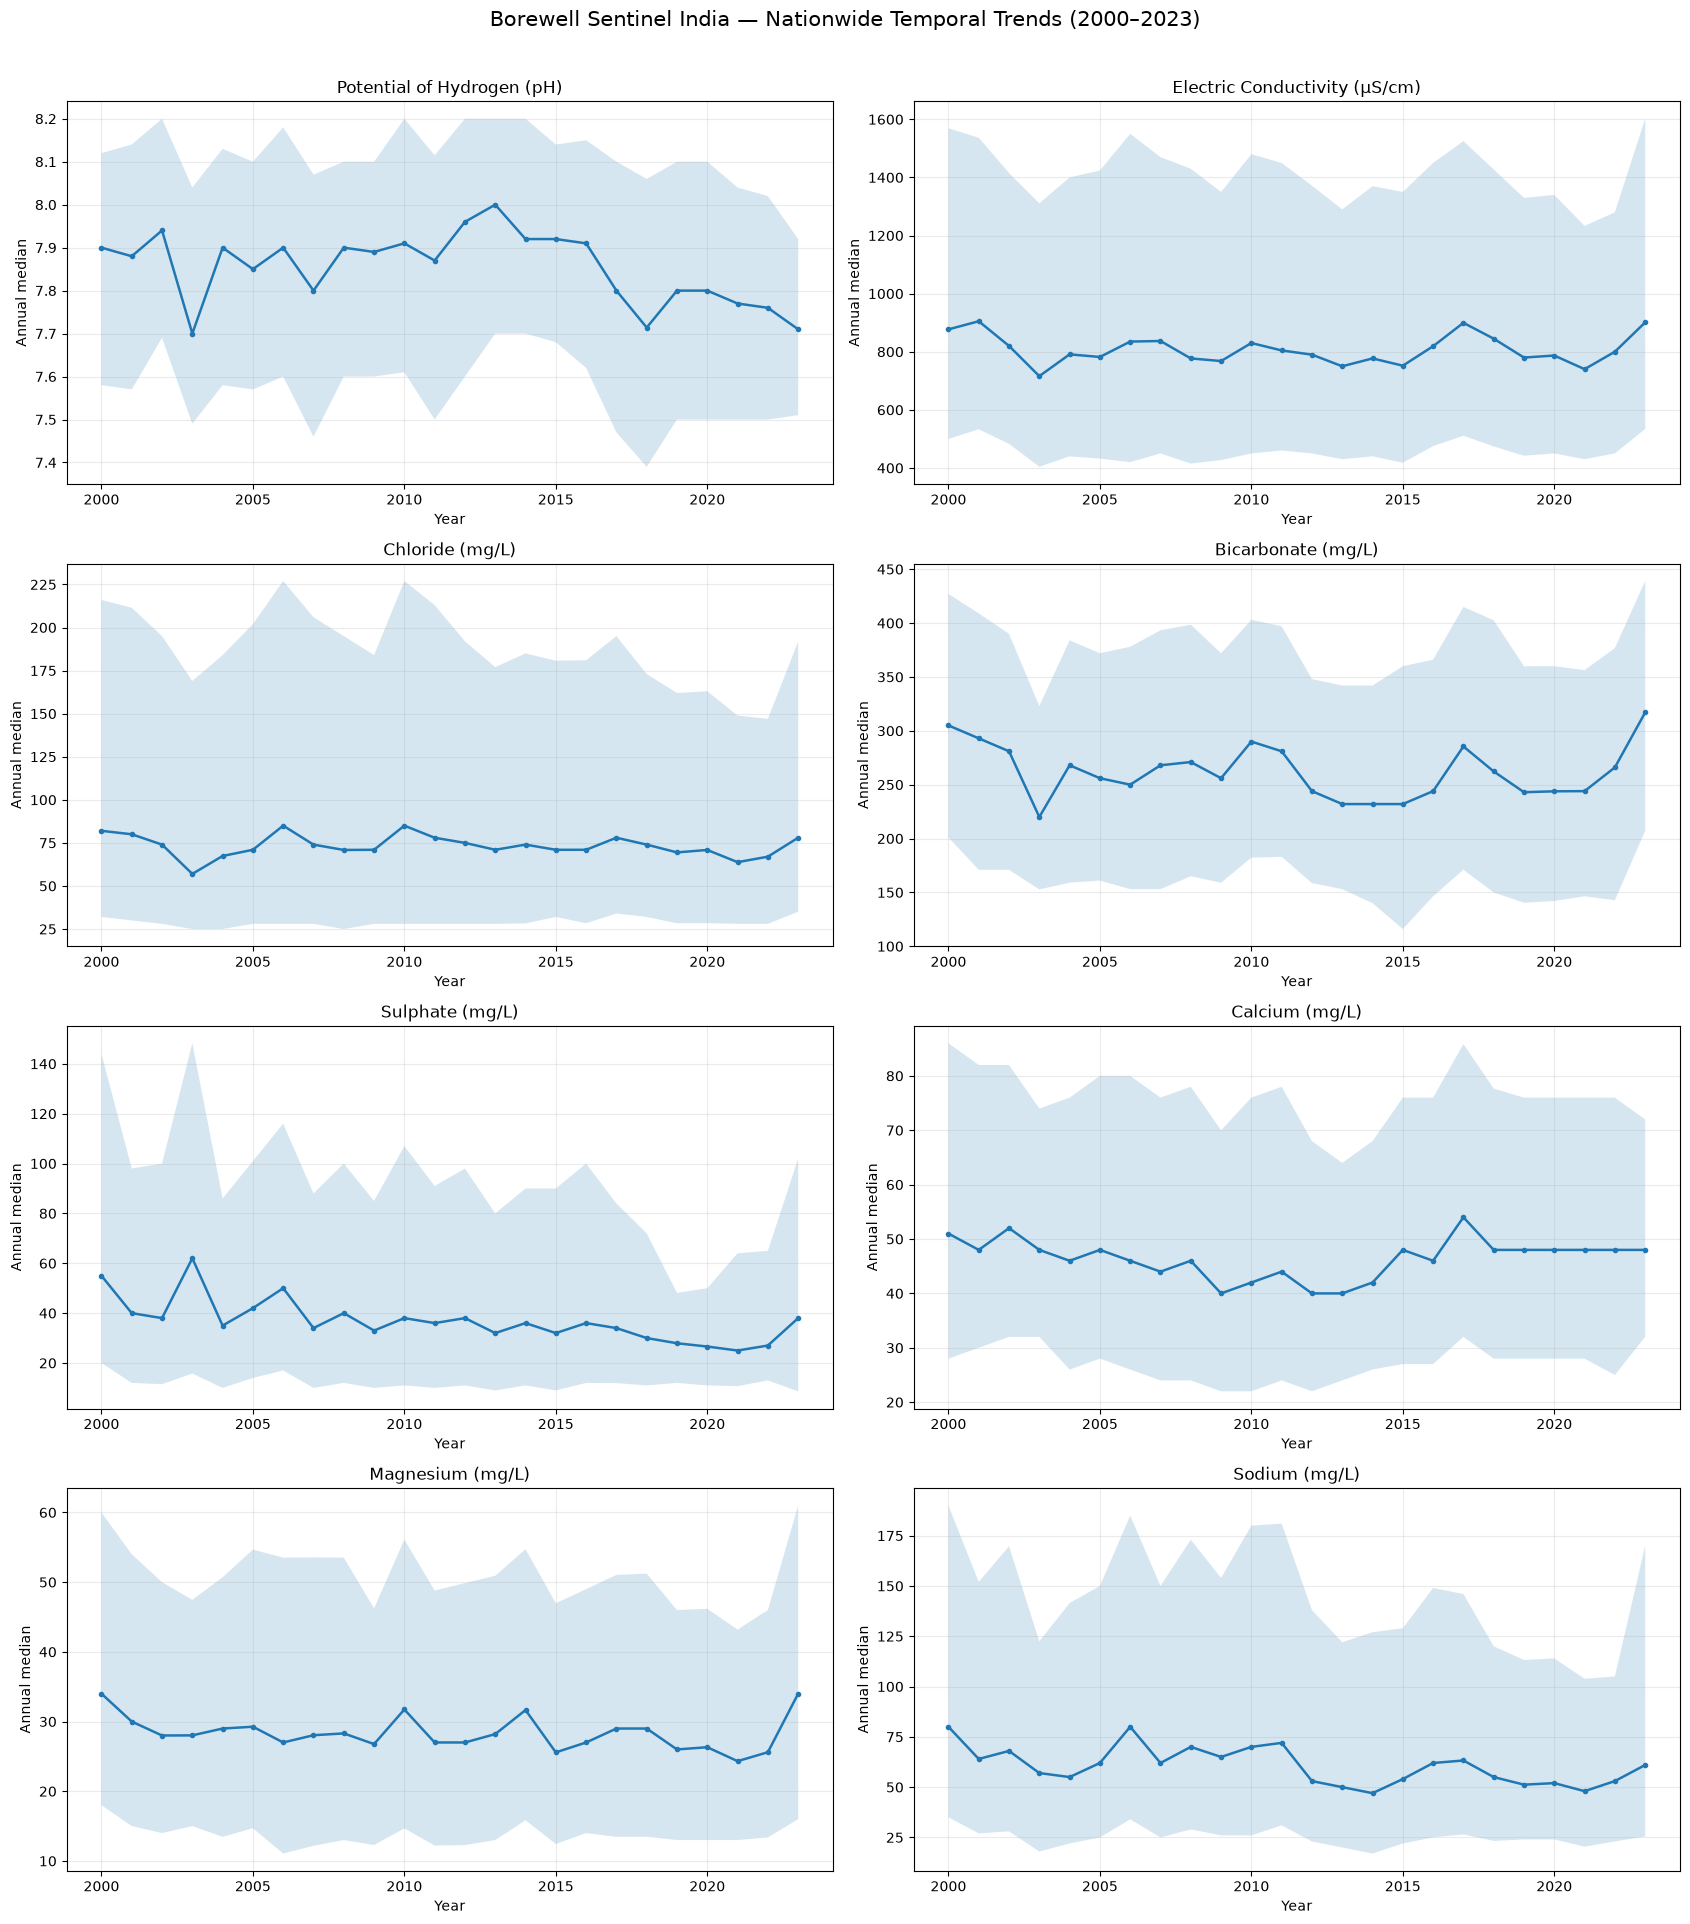

Saved: c:\career\projects\BoreWell Sentinel India\reports\temporal_analysis\phase_7\phase7_nationwide_annual_trends.png


In [29]:
TEMPORAL_REPORT_DIR = (
    PROJECT_ROOT / "reports" / "temporal_analysis" / "phase_7"
)

TEMPORAL_REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

fig, axes = plt.subplots(4, 2, figsize=(17, 19))
axes = axes.flatten()

for ax, target in zip(axes, TEMPORAL_TARGETS):

    valid_mask = target_validity[target].loc[analysis_df.index]

    valid_data = analysis_df.loc[
        valid_mask,
        ["_year", target]
    ]

    stats = (
        valid_data.groupby("_year")[target]
        .agg(
            Median="median",
            Q25=lambda x: x.quantile(0.25),
            Q75=lambda x: x.quantile(0.75)
        )
    )

    years = stats.index.to_numpy()

    ax.plot(
        years,
        stats["Median"],
        marker="o",
        markersize=3,
        linewidth=1.8
    )

    ax.fill_between(
        years,
        stats["Q25"].to_numpy(),
        stats["Q75"].to_numpy(),
        alpha=0.18
    )

    ax.set_title(target)
    ax.set_xlabel("Year")
    ax.set_ylabel("Annual median")
    ax.grid(alpha=0.25)

fig.suptitle(
    "Borewell Sentinel India — Nationwide Temporal Trends (2000–2023)",
    fontsize=15,
    y=1.01
)

fig.tight_layout()

ANNUAL_TREND_CHART = (
    TEMPORAL_REPORT_DIR / "phase7_nationwide_annual_trends.png"
)

fig.savefig(
    ANNUAL_TREND_CHART,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Saved:", ANNUAL_TREND_CHART)

In [30]:
# Annual nationwide statistics.
annual_median_df.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_annual_medians.csv"
)

annual_count_df.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_annual_valid_counts.csv"
)

annual_summary.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_annual_sampling_coverage.csv"
)

monthly_summary.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_monthly_sampling_distribution.csv"
)

# Location-specific trend results.
trend_results_df.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_location_trends_all_months.csv",
    index=False
)

may_trend_results_df.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_location_trends_may_only.csv",
    index=False
)

trend_counts.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_all_month_trend_counts.csv"
)

may_counts.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_may_only_trend_counts.csv"
)

may_sensitivity_df.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_trend_sensitivity_comparison.csv"
)

may_candidates_reviewed.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_significant_location_candidates.csv",
    index=False
)

location_review_register.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_location_review_register.csv",
    index=False
)

# Chronological forecasting outputs.
forecast_support_df.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_forecast_support.csv"
)

forecast_predictions_df.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_forecast_predictions.csv",
    index=False
)

forecast_evaluation_df.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_forecast_pooled_evaluation.csv"
)

forecast_bootstrap_df.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_forecast_pooled_bootstrap.csv"
)

location_weighted_df.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_forecast_location_weighted.csv"
)

robust_forecast_df.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_forecast_robust_diagnostics.csv"
)

robust_decision_df.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_forecasting_decisions.csv"
)

forecast_horizon_df.to_csv(
    TEMPORAL_REPORT_DIR / "phase7_forecast_yearly_performance.csv",
    index=False
)

print("PHASE 7 REPORT EXPORT COMPLETED")
print("=" * 75)
print("Output directory:", TEMPORAL_REPORT_DIR)

for path in sorted(TEMPORAL_REPORT_DIR.iterdir()):
    if path.is_file():
        print(
            f"{path.name:55s} "
            f"{path.stat().st_size / (1024**2):.2f} MB"
        )

PHASE 7 REPORT EXPORT COMPLETED
Output directory: c:\career\projects\BoreWell Sentinel India\reports\temporal_analysis\phase_7
phase7_all_month_trend_counts.csv                       0.00 MB
phase7_annual_medians.csv                               0.00 MB
phase7_annual_sampling_coverage.csv                     0.00 MB
phase7_annual_valid_counts.csv                          0.00 MB
phase7_forecast_location_weighted.csv                   0.00 MB
phase7_forecast_pooled_bootstrap.csv                    0.00 MB
phase7_forecast_pooled_evaluation.csv                   0.00 MB
phase7_forecast_predictions.csv                         11.12 MB
phase7_forecast_robust_diagnostics.csv                  0.00 MB
phase7_forecast_support.csv                             0.00 MB
phase7_forecast_yearly_performance.csv                  0.00 MB
phase7_forecasting_decisions.csv                        0.00 MB
phase7_location_review_register.csv                     0.00 MB
phase7_location_trends_all_months.csv   

In [31]:
phase7_files = [
    p for p in TEMPORAL_REPORT_DIR.iterdir()
    if p.is_file()
]

verification_df = pd.DataFrame({
    "Filename": [p.name for p in phase7_files],
    "Exists": [p.exists() for p in phase7_files],
    "Size (MB)": [
        round(p.stat().st_size / (1024**2), 3)
        for p in phase7_files
    ]
})

display(verification_df)

assert len(phase7_files) >= 15
assert verification_df["Exists"].all()

assert len(trend_results_df) == 98488
assert len(may_trend_results_df) == 97317
assert len(forecast_predictions_df) > 0

assert (
    location_review_register["Source_records"].sum() == 34
)

print("\nPHASE 7 OUTPUT VERIFICATION PASSED")

,Filename,Exists,Size (MB)
0,phase7_all_month_trend_counts.csv,True,0.000
1,phase7_annual_medians.csv,True,0.001
2,phase7_annual_sampling_coverage.csv,True,0.001
3,phase7_annual_valid_counts.csv,True,0.001
4,phase7_forecasting_decisions.csv,True,0.001
5,phase7_forecast_location_weighted.csv,True,0.001
6,phase7_forecast_pooled_bootstrap.csv,True,0.001
7,phase7_forecast_pooled_evaluation.csv,True,0.001
8,phase7_forecast_predictions.csv,True,11.124
9,phase7_forecast_robust_diagnostics.csv,True,0.001



PHASE 7 OUTPUT VERIFICATION PASSED


---

# Phase 7 — Completion Report

## Objective
Analyze historical groundwater chemical trends, repeated-location changes and future forecasting potential across India.

## Historical dataset
- Integrated records: 174,635.
- Historical analysis period: 2000–2023.
- May records: 170,960 in the analysis period.
- May represents approximately 97.9% of nationwide observations.
- Recent coverage in 2024–2025 was insufficient for reliable nationwide trend analysis.

## Location-specific trend analysis
- All-month analysis: 98,488 location-target combinations.
- May-only analysis: 97,317 location-target combinations.
- Trend estimation: Theil–Sen slope.
- Trend significance: Mann–Kendall test.
- Multiple-testing correction: Benjamini–Hochberg.
- Significant trends were most evident for Electrical Conductivity and Chloride.
- Many locations did not exhibit statistically significant monotonic trends.

## Trend sensitivity
Most significant Electrical Conductivity and Chloride trends remained significant and retained their direction in the May-only sensitivity analysis.

## Forecasting experiment
- Training period: 2000–2018.
- Test period: 2019–2023.
- Evaluation population: May-only annual location medians.
- Eligible locations ranged from 1,787 to 5,081, depending on the target.
- Compared persistence against Theil–Sen extrapolation.
- Used spatial-group bootstrap confidence intervals and equal-weighted location analysis.

## Forecasting conclusions
- Persistence remains the preferred default at most individual locations.
- Trend extrapolation showed some pooled improvements, but these were not consistently observed at the typical location.
- No universal trend-forecasting improvement was established.
- Location-specific forecast experiments should be treated as exploratory.

## Location data-quality findings
Two station records were found to have mismatched administrative metadata:
- NOHAR1: corroborated as Nohar, Hanumangarh, Rajasthan.
- Wyala: corroborated as Akola, Maharashtra.

Original source values and IDs remain unchanged. A separate location-review register preserves the reviewed display references.

## Important limitations
- Strong May sampling concentration prevents dependable nationwide seasonal analysis.
- Provisional spatial groups are not confirmed well identities.
- Temporal autocorrelation has not been fully modeled in the significance tests.
- Forecast testing used one chronological cutoff rather than rolling-origin validation.
- Significant trends do not establish causes or prove contamination deterioration.
- Forecast estimates are not substitutes for new laboratory measurements.

## Saved outputs
All Phase 7 outputs are stored in:
`reports/temporal_analysis/phase_7/`

## Phase status
COMPLETED — Phase 7 of 11.